# Perbandingan decision tree, SVM, ANN, dan CNN pada klasifikasi Income

In [1]:
import time
import random
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import binomtest

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")

randomState = 42
random.seed(randomState)
np.random.seed(randomState)
torch.manual_seed(randomState)

# satu thread + algoritma deterministik supaya CNN bisa diulang persis di mesin yang sama
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 10

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)

In [2]:
import platform
import sklearn

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | torch {torch.__version__}")
print(f"Platform: {platform.platform()}")

Python 3.14.6 | numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1 | torch 2.15.0
Platform: macOS-27.2-arm64-arm-64bit-Mach-O


# Eksplorasi data (EDA)

dataset: Income classification (Kaggle)

| atribut | keterangan |
|---|---|
| **nama** | Income classification |
| **sumber** | Kaggle, https://www.kaggle.com/datasets/lodetomasi1995/income-classification |
| **berkas** | `income_evaluation.csv` (3,8 MB) |
| **jumlah instance** | 32.561 |
| **jumlah atribut** | 15 (6 numerik + 8 kategorik + 1 target) |
| **tugas** | klasifikasi biner: apakah penghasilan seseorang per tahun lebih dari 50K atau tidak |
| **lisensi** | tidak disebutkan di halaman Kaggle (Unknown), jadi berkasnya tidak disertakan di repositori |

variabel (nama kolom asli yang pakai tanda hubung diganti camelCase, mis. `education-num` jadi `educationNum`)

| variabel | tipe | keterangan |
|---|---|---|
| `age` | numerik | usia |
| `workclass` | kategorik | jenis atau sektor pekerjaan (swasta, pemerintah, wiraswasta, dan seterusnya) |
| `fnlwgt` | numerik | bobot sampling dari sensus (perkiraan jumlah orang yang diwakili satu baris), bukan ciri orangnya |
| `education` | kategorik | jenjang pendidikan tertinggi |
| `educationNum` | numerik (ordinal) | jenjang pendidikan yang sama dalam angka 1 sampai 16 |
| `maritalStatus` | kategorik | status pernikahan |
| `occupation` | kategorik | bidang pekerjaan |
| `relationship` | kategorik | peran dalam keluarga (suami, istri, anak, dan seterusnya) |
| `race` | kategorik | ras |
| `sex` | kategorik | jenis kelamin |
| `capitalGain` | numerik | keuntungan modal (penjualan aset dan sejenisnya) |
| `capitalLoss` | numerik | kerugian modal |
| `hoursPerWeek` | numerik | jam kerja per minggu |
| `nativeCountry` | kategorik | negara asal |
| `income` | kategorik (target) | `<=50K` atau `>50K` |

In [3]:
namaBerkas = "income_evaluation.csv"

# baca dari folder yang sama dengan notebook (atau folder data/), berkas diunduh manual dari Kaggle
def muatDataset() -> pd.DataFrame:
    for lokasi in (Path(namaBerkas), Path("data") / namaBerkas):
        if lokasi.exists():
            print(f"Memakai berkas lokal: {lokasi}")
            # skipinitialspace: di berkas aslinya ada spasi setelah tiap koma
            return pd.read_csv(lokasi, skipinitialspace=True)
    raise FileNotFoundError(
        f"{namaBerkas} tidak ditemukan. Unduh dari "
        "https://www.kaggle.com/datasets/lodetomasi1995/income-classification "
        "lalu taruh di folder yang sama dengan notebook ini.")

df = muatDataset()

# nama kolom asli pakai tanda hubung, diganti camelCase supaya bisa dipakai sebagai nama variabel
df = df.rename(columns={
    "education-num": "educationNum", "marital-status": "maritalStatus",
    "capital-gain": "capitalGain", "capital-loss": "capitalLoss",
    "hours-per-week": "hoursPerWeek", "native-country": "nativeCountry",
})

Memakai berkas lokal: income_evaluation.csv


In [4]:
# definisikan fitur sama target
target = "income"
fiturNumerik = ["age", "fnlwgt", "educationNum", "capitalGain", "capitalLoss", "hoursPerWeek"]
fiturKategorik = ["workclass", "education", "maritalStatus", "occupation", "relationship", "race", "sex", "nativeCountry"]
warna = {"<=50K": "#2E86AB", ">50K": "#E4572E"}

print(f"Dimensi  : {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Fitur numerik ({len(fiturNumerik)}): {', '.join(fiturNumerik)}")
print(f"Fitur kategorik ({len(fiturKategorik)}): {', '.join(fiturKategorik)}")
print(f"Target            : {target}")
print("\nLima baris pertama:")
df.head()

Dimensi  : 32,561 baris x 15 kolom
Fitur numerik (6): age, fnlwgt, educationNum, capitalGain, capitalLoss, hoursPerWeek
Fitur kategorik (8): workclass, education, maritalStatus, occupation, relationship, race, sex, nativeCountry
Target            : income

Lima baris pertama:


,age,workclass,fnlwgt,education,educationNum,maritalStatus,occupation,relationship,race,sex,capitalGain,capitalLoss,hoursPerWeek,nativeCountry,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


struktur dataframe

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   age            32561 non-null  int64
 1   workclass      32561 non-null  str  
 2   fnlwgt         32561 non-null  int64
 3   education      32561 non-null  str  
 4   educationNum   32561 non-null  int64
 5   maritalStatus  32561 non-null  str  
 6   occupation     32561 non-null  str  
 7   relationship   32561 non-null  str  
 8   race           32561 non-null  str  
 9   sex            32561 non-null  str  
 10  capitalGain    32561 non-null  int64
 11  capitalLoss    32561 non-null  int64
 12  hoursPerWeek   32561 non-null  int64
 13  nativeCountry  32561 non-null  str  
 14  income         32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


statistik deskriptif untuk tau sebaran data

In [6]:
display(df[fiturNumerik].describe().T.round(2))
display(df[fiturKategorik].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0
educationNum,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capitalGain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0
capitalLoss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0
hoursPerWeek,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0


,count,unique,top,freq
workclass,32561,9,Private,22696
education,32561,16,HS-grad,10501
maritalStatus,32561,7,Married-civ-spouse,14976
occupation,32561,15,Prof-specialty,4140
relationship,32561,6,Husband,13193
race,32561,5,White,27816
sex,32561,2,Male,21790
nativeCountry,32561,42,United-States,29170


skala antar-fitur timpang: rata-rata `fnlwgt` sekitar 189.778 sedangkan `educationNum` cuma sekitar 10. `capitalGain` dan `capitalLoss` bahkan nol pada lebih dari tiga perempat baris (kuartil ketiganya 0), tapi maksimumnya 99.999 dan 4.356. fitur seperti ini akan didominasi fitur berskala besar di SVM dan jaringan saraf kalau tidak distandardisasi.

di sisi kategorik, `Private` mendominasi `workclass` (22.696 dari 32.561, sekitar 70%), `White` sekitar 85% dari `race`, laki-laki sekitar 67%, dan `United-States` sekitar 90% dari `nativeCountry`. `nativeCountry` punya 42 nilai, kebanyakan sangat jarang, jadi perlu digabung waktu di-encode.

cek missing value & duplikat

In [7]:
cekData = pd.DataFrame({
    "tipeData":      df.dtypes.astype(str),
    "jumlahMissing": df.isna().sum(),
    "jumlahTanya":   (df == "?").sum(),
    "nilaiUnik":     df.nunique(),
})
display(cekData)

print(f"\nTotal sel kosong (NaN) di seluruh tabel : {int(df.isna().sum().sum())}")
print(f"Total sel berisi '?'                    : {int((df == '?').sum().sum())}")
print(f"Jumlah baris duplikat penuh             : {int(df.duplicated().sum())} ({df.duplicated().mean() * 100:.2f}%)")
print(f"Jumlah nilai negatif pada fitur numerik : {int((df[fiturNumerik] < 0).sum().sum())}")

,tipeData,jumlahMissing,jumlahTanya,nilaiUnik
age,int64,0,0,73
workclass,str,0,1836,9
fnlwgt,int64,0,0,21648
education,str,0,0,16
educationNum,int64,0,0,16
maritalStatus,str,0,0,7
occupation,str,0,1843,15
relationship,str,0,0,6
race,str,0,0,5
sex,str,0,0,2



Total sel kosong (NaN) di seluruh tabel : 0
Total sel berisi '?'                    : 4262
Jumlah baris duplikat penuh             : 24 (0.07%)
Jumlah nilai negatif pada fitur numerik : 0


tidak ada sel kosong (NaN), tapi dataset ini menulis data yang tidak diketahui sebagai `?`: 4.262 sel, semuanya di tiga kolom (`workclass` 1.836, `occupation` 1.843, `nativeCountry` 583). ini bukan missing value yang kebaca otomatis oleh pandas, jadi harus ditangani sendiri. ada juga 24 baris duplikat penuh (0,07%), dan tidak ada nilai negatif.

distribusi kelas (target)

income
<=50K    24720
>50K      7841

Proporsi kelas >50K : 24.08%
Rasio ketidakseimbangan (mayoritas / minoritas) : 3.15


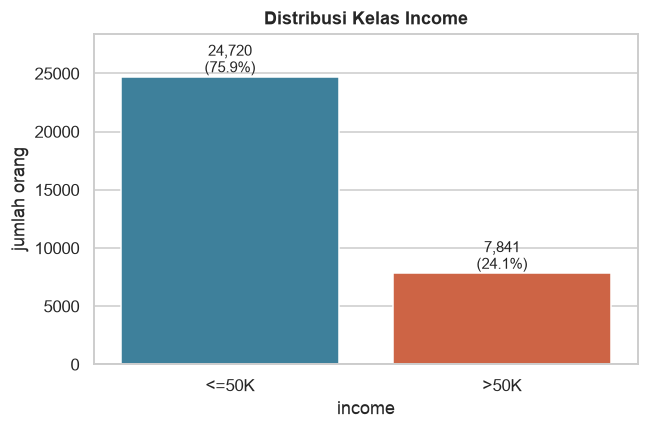

In [8]:
jumlahKelas = df[target].value_counts()
print(jumlahKelas.to_string())
print(f"\nProporsi kelas >50K : {jumlahKelas['>50K'] / len(df) * 100:.2f}%")
print(f"Rasio ketidakseimbangan (mayoritas / minoritas) : {jumlahKelas.max() / jumlahKelas.min():.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=jumlahKelas.index, y=jumlahKelas.values, palette=[warna[k] for k in jumlahKelas.index], ax=ax)
for i, v in enumerate(jumlahKelas.values):
    ax.text(i, v, f"{v:,}\n({v / len(df) * 100:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, jumlahKelas.max() * 1.15)
ax.set_title("Distribusi Kelas Income")
ax.set_ylabel("jumlah orang")
plt.tight_layout()
plt.show()

kelasnya tidak seimbang: `<=50K` 24.720 orang (75,9%) dan `>50K` 7.841 orang (24,1%), rasio 3,15. ini tidak seekstrem data langka, tapi cukup untuk menyesatkan akurasi: model yang selalu menebak `<=50K` sudah akurat 75,9% tanpa belajar apa-apa. makanya precision, recall, dan F1 untuk kelas `>50K` dilaporkan terpisah, dan split data nanti pakai stratify supaya proporsinya sama di data latih dan uji.

distribusi tiap fitur numerik

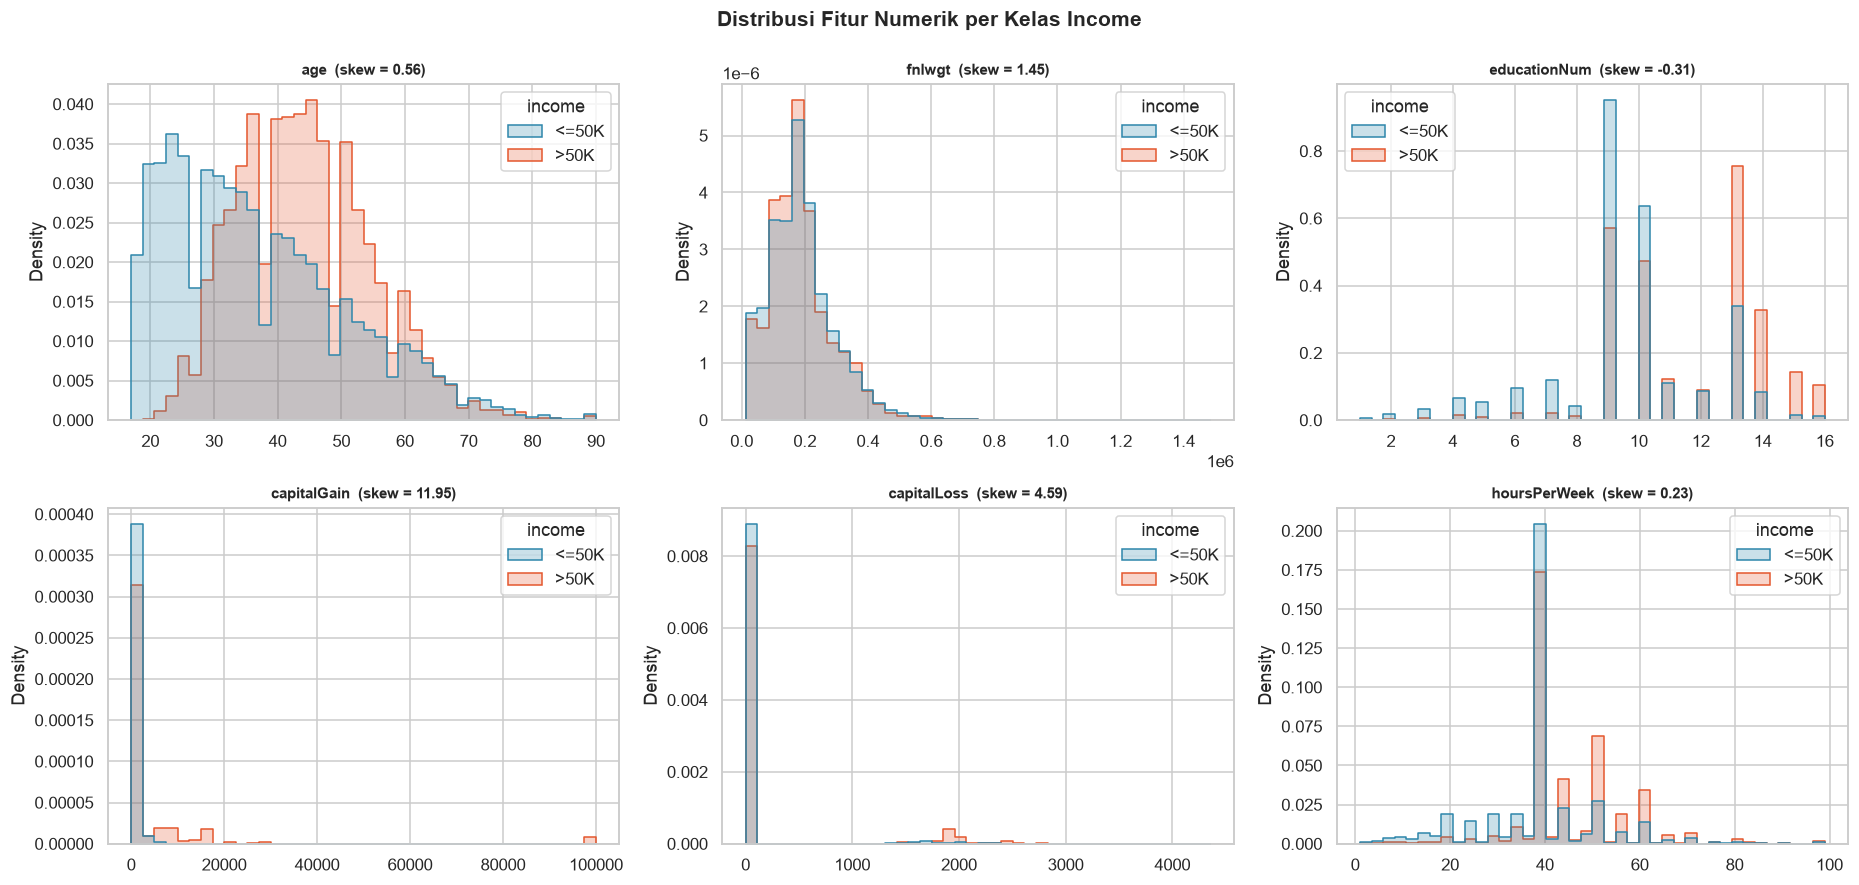

Median per kelas income:


,age,educationNum,hoursPerWeek
income,,,
<=50K,34.0,9.0,40.0
>50K,44.0,12.0,40.0


Persentase orang yang kerja tepat 40 jam per minggu : 46.7%
Persentase baris dengan capitalGain > 0 per kelas income:
income
<=50K     4.2
>50K     21.4


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, kolom in zip(axes.ravel(), fiturNumerik):
    sns.histplot(data=df, x=kolom, hue=target, bins=40, element="step", stat="density",
                 common_norm=False, palette=warna, ax=ax)
    ax.set_title(f"{kolom}  (skew = {df[kolom].skew():.2f})", fontsize=10)
    ax.set_xlabel("")

fig.suptitle("Distribusi Fitur Numerik per Kelas Income", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

print("Median per kelas income:")
display(df.groupby(target)[["age", "educationNum", "hoursPerWeek"]].median())
print(f"Persentase orang yang kerja tepat 40 jam per minggu : {(df['hoursPerWeek'] == 40).mean() * 100:.1f}%")
print("Persentase baris dengan capitalGain > 0 per kelas income:")
print((df["capitalGain"].gt(0).groupby(df[target]).mean() * 100).round(1).to_string())

beberapa pola yang kelihatan dari histogram per kelas:

- `age`: kelas `>50K` bergeser ke usia lebih tinggi (puncak sekitar 35 sampai 50 tahun), sedangkan `<=50K` banyak di usia 20-an. median usianya 44 vs 34 tahun.
- `educationNum`: kelas `>50K` punya puncak di 13 (Bachelors) dan lebih banyak di 14 sampai 16, sedangkan `<=50K` menumpuk di 9 dan 10 (lulusan SMA dan kuliah tanpa gelar).
- `hoursPerWeek`: puncak tajam di 40 jam untuk kedua kelas (46,7% orang kerja tepat 40 jam), tapi `>50K` lebih banyak di 50 sampai 60 jam.
- `capitalGain` dan `capitalLoss`: hampir semua nol, dengan ekor panjang (skew 11,95 dan 4,59). yang punya `capitalGain` > 0 lebih banyak di `>50K` (21,4% vs 4,2%).
- `fnlwgt`: distribusinya nyaris sama untuk kedua kelas, jadi kelihatannya tidak membawa informasi soal penghasilan.

distribusi fitur kategorik dan peluang income >50K

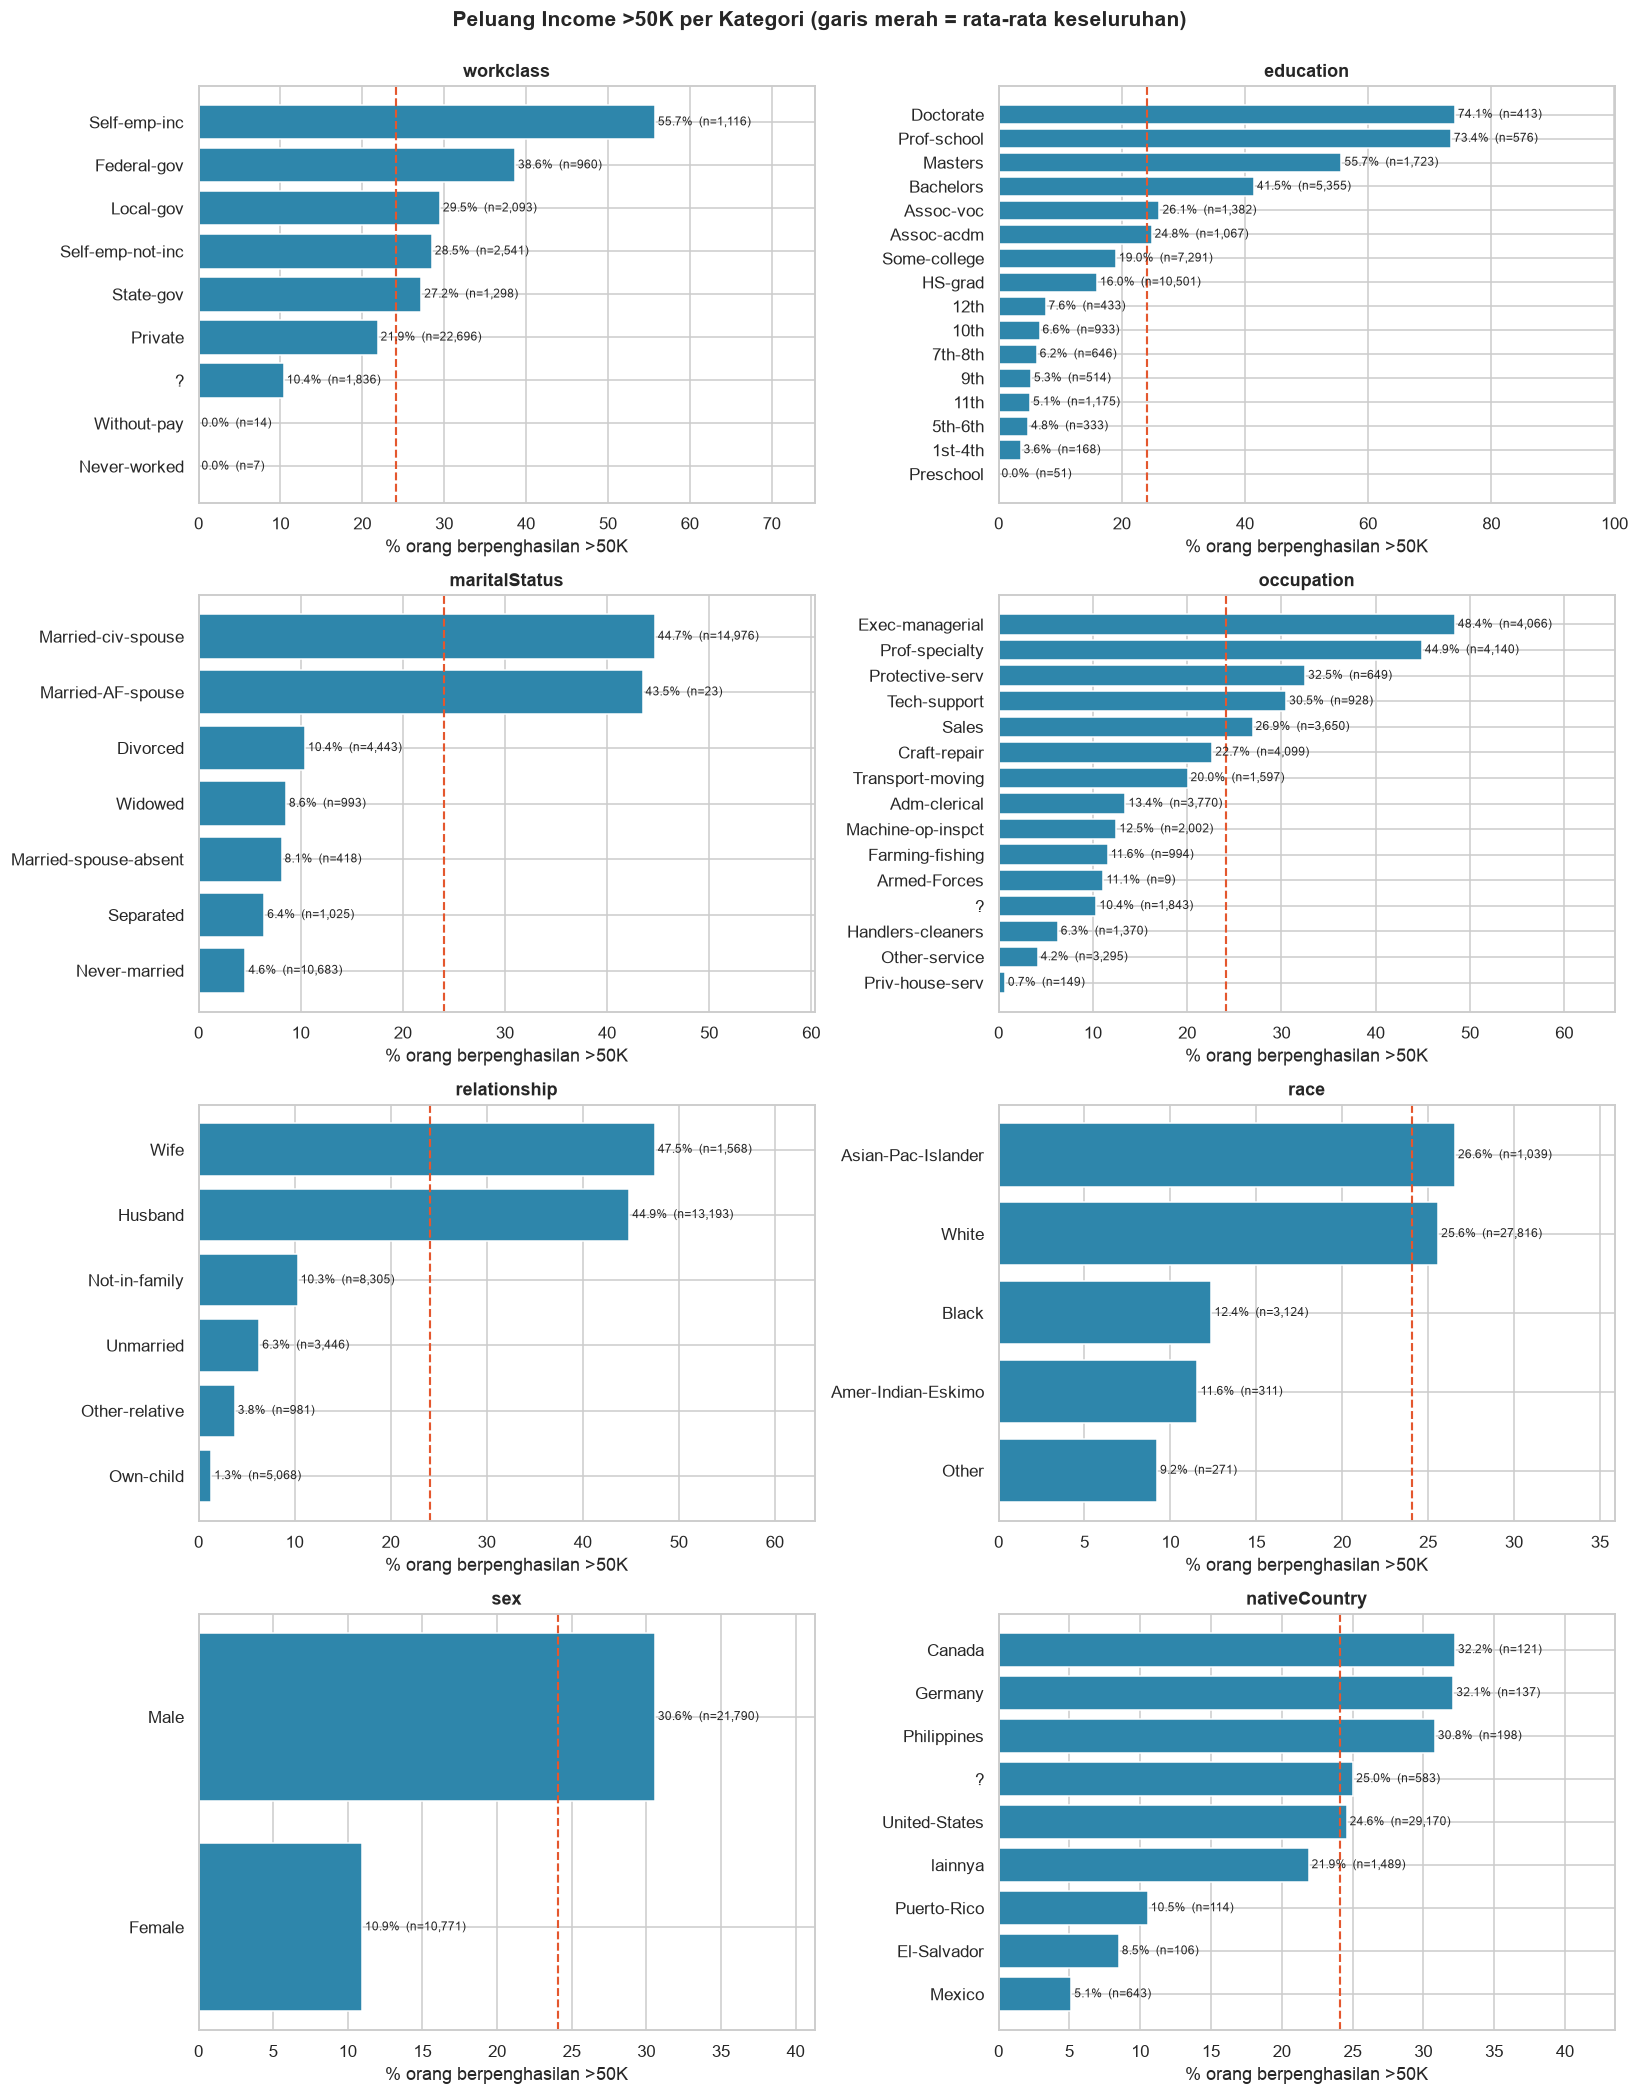

In [10]:
persenAtas = (df[target] == ">50K").mean() * 100

fig, axes = plt.subplots(4, 2, figsize=(15, 19))
for ax, kolom in zip(axes.ravel(), fiturKategorik):
    seri = df[kolom]
    # nativeCountry punya 42 nilai, tampilkan 8 terbanyak dan sisanya digabung jadi "lainnya"
    if seri.nunique() > 20:
        seri = seri.where(seri.isin(seri.value_counts().index[:8]), "lainnya")
    peluang = (df[target].eq(">50K").groupby(seri).mean() * 100).sort_values()
    jumlah = seri.value_counts()
    ax.barh(peluang.index, peluang.values, color="#2E86AB")
    ax.axvline(persenAtas, color="#E4572E", ls="--", lw=1.4)
    for i, (nilai, p) in enumerate(peluang.items()):
        ax.text(p, i, f" {p:.1f}%  (n={jumlah[nilai]:,})", va="center", fontsize=8)
    ax.set_xlim(0, peluang.max() * 1.35)
    ax.set_title(kolom)
    ax.set_xlabel("% orang berpenghasilan >50K")

fig.suptitle("Peluang Income >50K per Kategori (garis merah = rata-rata keseluruhan)",
             fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

peluang berpenghasilan `>50K` sangat berbeda antar kategori, dan banyak yang jauh dari rata-rata 24,1% (garis merah):

- `education`: semakin tinggi semakin besar. `Doctorate` 74,1%, `Prof-school` 73,4%, `Masters` 55,7%, `Bachelors` 41,5%, sedangkan `HS-grad` 16,0% dan jenjang di bawahnya di bawah 8%.
- `maritalStatus` dan `relationship`: `Married-civ-spouse` 44,7%, `Husband` 44,9%, `Wife` 47,5%, sedangkan `Never-married` cuma 4,6% dan `Own-child` 1,3%. sekitar 85% orang `>50K` berstatus `Married-civ-spouse`.
- `occupation` dan `workclass`: `Exec-managerial` 48,4% dan `Prof-specialty` 44,9%, sedangkan `Other-service` 4,2%. wiraswasta berbadan usaha (`Self-emp-inc`) 55,7%.
- `sex`: laki-laki 30,6% vs perempuan 10,9%. `race`: `White` 25,6% dan `Asian-Pac-Islander` 26,6% vs `Black` 12,4%.
- `nativeCountry` ditampilkan 8 negara terbanyak, sisanya digabung jadi `lainnya` supaya terbaca.

hampir semua fitur kategorik informatif, jadi dipertahankan. `education` perlu dicek lebih lanjut karena kembar dengan `educationNum` (bagian bawah).

nilai '?' (data tidak diketahui)

In [11]:
kolomTanya = [k for k in fiturKategorik if (df[k] == "?").any()]
baris = []
for k in kolomTanya:
    tanya = df[k] == "?"
    baris.append({
        "kolom": k,
        "jumlahTanya": int(tanya.sum()),
        "persenTanya": round(tanya.mean() * 100, 2),
        "persenAtas50kJikaTanya": round((df.loc[tanya, target] == ">50K").mean() * 100, 2),
        "persenAtas50kJikaLengkap": round((df.loc[~tanya, target] == ">50K").mean() * 100, 2),
    })
display(pd.DataFrame(baris).set_index("kolom"))

barisAdaTanya = (df[kolomTanya] == "?").any(axis=1)
print(f"\nBaris dengan >=1 nilai '?' : {int(barisAdaTanya.sum()):,} dari {len(df):,} ({barisAdaTanya.mean() * 100:.1f}%)")
print("Baris dengan '?' di workclass juga '?' di occupation :",
      f"{int(((df['workclass'] == '?') & (df['occupation'] == '?')).sum()):,} dari {int((df['workclass'] == '?').sum()):,}")

,jumlahTanya,persenTanya,persenAtas50kJikaTanya,persenAtas50kJikaLengkap
kolom,,,,
workclass,1836,5.64,10.40,24.90
occupation,1843,5.66,10.36,24.90
nativeCountry,583,1.79,25.04,24.06



Baris dengan >=1 nilai '?' : 2,399 dari 32,561 (7.4%)
Baris dengan '?' di workclass juga '?' di occupation : 1,836 dari 1,836


nilai `?` ternyata bukan acak. orang dengan `workclass` atau `occupation` `?` cuma 10,4% yang berpenghasilan `>50K`, jauh di bawah 24,9% pada yang lengkap. semua baris dengan `workclass` `?` (1.836) juga `?` di `occupation`, jadi kemungkinan ini orang yang pekerjaannya tidak tercatat (misalnya tidak bekerja atau data kosong sekaligus). `nativeCountry` `?` justru tidak beda (25,0% vs 24,1%).

dampaknya: kalau `?` diimputasi dengan modus (`Private`, `Prof-specialty`), sinyal bahwa kelompok ini jarang berpenghasilan tinggi ikut hilang. total 2.399 baris (7,4%) terdampak, terlalu banyak untuk dibuang. keputusannya `?` dijadikan kategori tersendiri bernama `tidakDiketahui`.

outlier dengan metode IQR

,Q1,Q3,IQR,batasBawah,batasAtas,nOutlier,persenOutlier
variabel,,,,,,,
hoursPerWeek,40.0,45.0,5.0,32.5,52.5,9008,27.66
capitalGain,0.0,0.0,0.0,0.0,0.0,2712,8.33
capitalLoss,0.0,0.0,0.0,0.0,0.0,1519,4.67
educationNum,9.0,12.0,3.0,4.5,16.5,1198,3.68
fnlwgt,117827.0,237051.0,119224.0,-61009.0,415887.0,992,3.05
age,28.0,48.0,20.0,-2.0,78.0,143,0.44


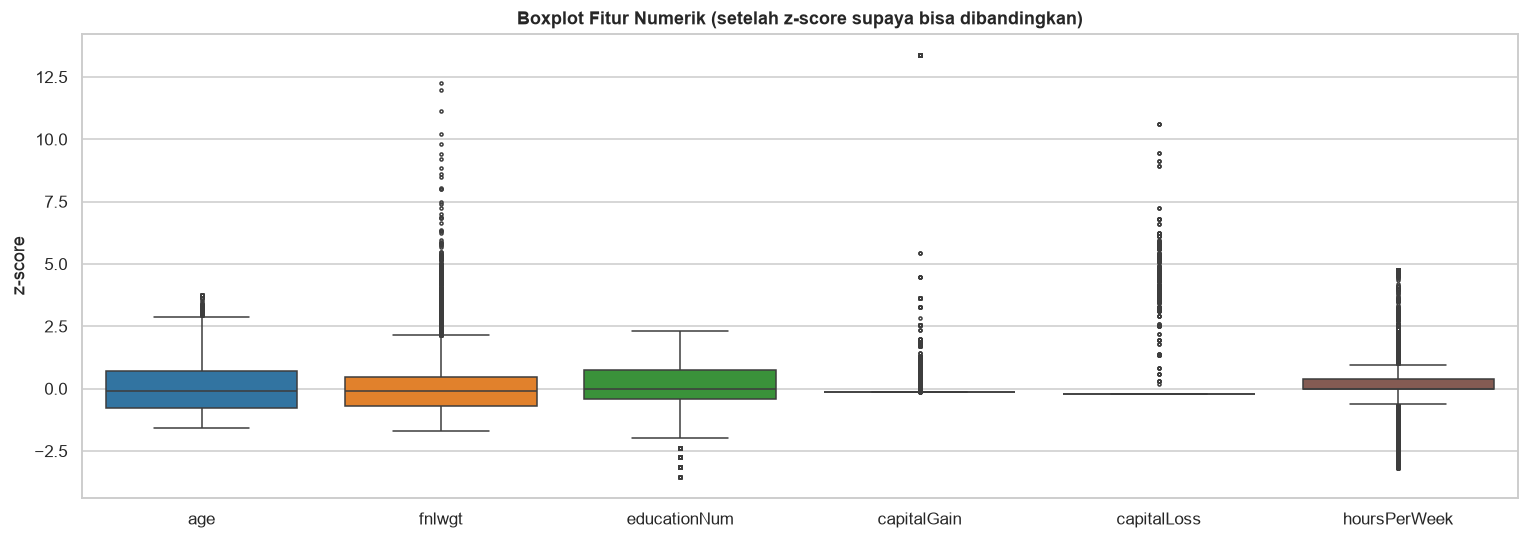

In [12]:
def deteksiOutlierIqr(data: pd.DataFrame, kolom: list[str], pengali: float = 1.5) -> pd.DataFrame:
    baris = []
    for k in kolom:
        q1, q3 = data[k].quantile(.25), data[k].quantile(.75)
        iqr = q3 - q1
        bawah, atas = q1 - pengali * iqr, q3 + pengali * iqr
        diLuar = (data[k] < bawah) | (data[k] > atas)
        baris.append({
            "variabel": k, "Q1": q1, "Q3": q3, "IQR": iqr,
            "batasBawah": bawah, "batasAtas": atas,
            "nOutlier": int(diLuar.sum()),
            "persenOutlier": round(diLuar.mean() * 100, 2),
        })
    return pd.DataFrame(baris).set_index("variabel")

ringkasOutlier = deteksiOutlierIqr(df, fiturNumerik)
display(ringkasOutlier.sort_values("persenOutlier", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(14, 5))
zScore = (df[fiturNumerik] - df[fiturNumerik].mean()) / df[fiturNumerik].std()
sns.boxplot(data=zScore, ax=ax, palette="tab10", fliersize=2, linewidth=1)
ax.set_title("Boxplot Fitur Numerik (setelah z-score supaya bisa dibandingkan)")
ax.set_ylabel("z-score")
plt.tight_layout()
plt.show()

menurut aturan IQR, `hoursPerWeek` punya 27,7% outlier, `capitalGain` 8,3%, `capitalLoss` 4,7%, `educationNum` 3,7%, `fnlwgt` 3,1%, dan `age` 0,4%. tapi angka ini perlu dibaca hati-hati:

- `hoursPerWeek`: IQR-nya sempit (40 sampai 45 jam) karena hampir separuh orang bekerja tepat 40 jam, jadi 30 atau 60 jam langsung dianggap outlier padahal wajar.
- `capitalGain` dan `capitalLoss`: Q1, Q3, dan IQR-nya nol karena mayoritas nol, jadi setiap nilai positif otomatis dianggap outlier. ini bukan kesalahan data, melainkan memang kebanyakan orang tidak punya keuntungan atau kerugian modal.
- `age` (maks 90) dan `educationNum` (rendah) adalah nilai yang masuk akal.

jadi hampir semua "outlier" menurut IQR adalah nilai valid, kecuali satu hal yang dibahas di bawah (nilai 99.999 pada `capitalGain`).

capital gain dan capital loss

,persenNol,median (nilai >0),maks,skewAsli,skewSetelahLog1p
capitalGain,91.67,7298.0,99999,11.95,3.10
capitalLoss,95.33,1887.0,4356,4.59,4.31



Baris dengan capitalGain = 99,999 : 159, 100.0% di antaranya berpenghasilan >50K
Usia maksimum : 90 (43 orang), jam kerja per minggu maksimum : 99 (85 orang)


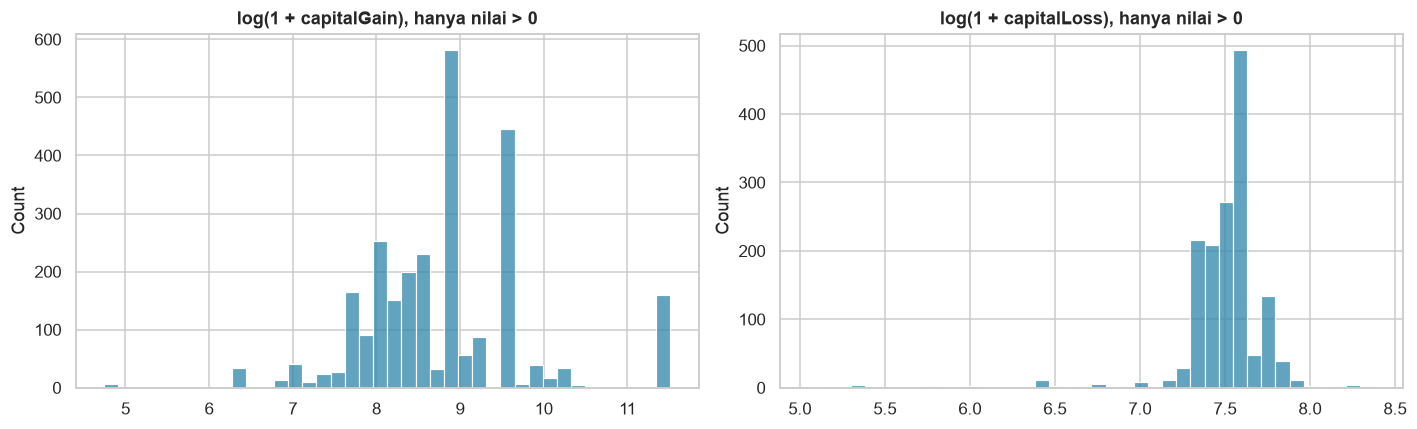

In [13]:
rincian = pd.DataFrame({
    "persenNol":         [(df[k] == 0).mean() * 100 for k in ["capitalGain", "capitalLoss"]],
    "median (nilai >0)": [df.loc[df[k] > 0, k].median() for k in ["capitalGain", "capitalLoss"]],
    "maks":              [df[k].max() for k in ["capitalGain", "capitalLoss"]],
    "skewAsli":          [df[k].skew() for k in ["capitalGain", "capitalLoss"]],
    "skewSetelahLog1p":  [np.log1p(df[k]).skew() for k in ["capitalGain", "capitalLoss"]],
}, index=["capitalGain", "capitalLoss"])
display(rincian.round(2))

atas = df["capitalGain"] == df["capitalGain"].max()
print(f"\nBaris dengan capitalGain = {df['capitalGain'].max():,} : {int(atas.sum())}, "
      f"{(df.loc[atas, target] == '>50K').mean() * 100:.1f}% di antaranya berpenghasilan >50K")
print(f"Usia maksimum : {df['age'].max()} ({int((df['age'] == df['age'].max()).sum())} orang), "
      f"jam kerja per minggu maksimum : {df['hoursPerWeek'].max()} ({int((df['hoursPerWeek'] == df['hoursPerWeek'].max()).sum())} orang)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, k in zip(axes, ["capitalGain", "capitalLoss"]):
    sns.histplot(np.log1p(df.loc[df[k] > 0, k]), bins=40, color="#2E86AB", ax=ax)
    ax.set_title(f"log(1 + {k}), hanya nilai > 0")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

`capitalGain` nol pada 91,7% baris dan `capitalLoss` pada 95,3%. kalau tidak nol, nilainya jauh lebih besar (median 7.298 dan 1.887). skew-nya 11,95 dan 4,59, jadi sangat miring ke kanan.

ada 159 baris dengan `capitalGain` tepat 99.999, dan semuanya (100%) berpenghasilan `>50K`. angka bulat ini kelihatannya batas atas pencatatan (nilai yang dipotong), bukan nilai sebenarnya, tapi informasinya tetap valid: orang dengan keuntungan modal sebesar itu pasti berpenghasilan tinggi. dibuang atau di-cap berarti membuang sinyal terkuat yang ada.

yang dilakukan: transformasi `log(1 + x)` pada kedua fitur ini. skew `capitalGain` turun dari 11,95 menjadi 3,10, jadi satu nilai 99.999 tidak lagi mendominasi skala setelah standardisasi. untuk `capitalLoss` skew-nya hanya turun dari 4,59 ke 4,31, karena pembedanya (nol vs bukan nol) memang tidak bisa dihilangkan oleh log, tapi transformasinya tetap dipakai supaya keduanya diperlakukan sama. outlier lain (`hoursPerWeek`, `age`) dipertahankan karena wajar.

korelasi antar fitur numerik

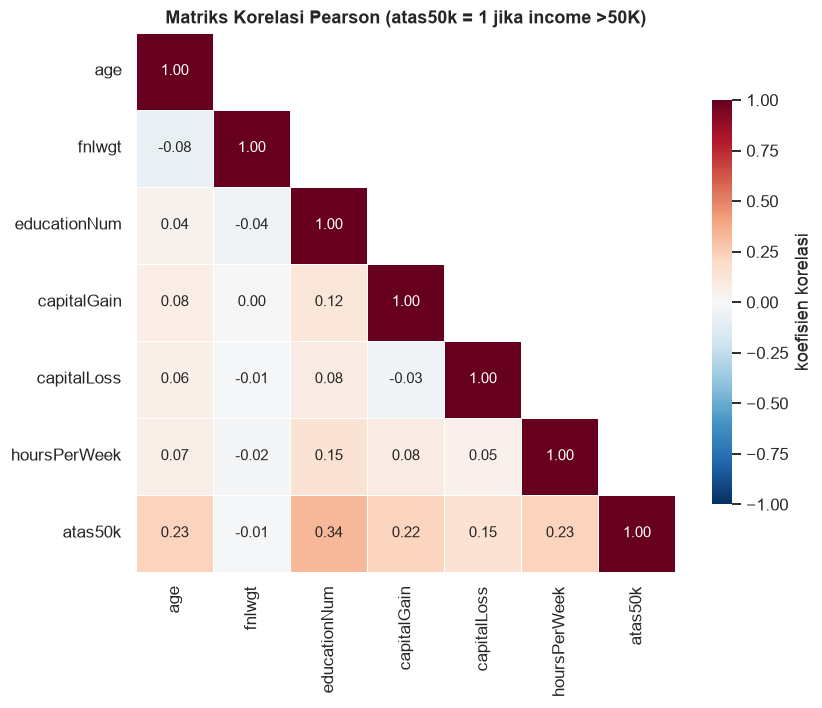

Korelasi tiap fitur numerik dengan atas50k:
educationNum    0.335
age             0.234
hoursPerWeek    0.230
capitalGain     0.223
capitalLoss     0.151
fnlwgt         -0.009


In [14]:
dfKorelasi = df[fiturNumerik].assign(atas50k=(df[target] == ">50K").astype(int))
korelasi = dfKorelasi.corr()
mask = np.triu(np.ones_like(korelasi, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(korelasi, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5,
            cbar_kws={"shrink": .75, "label": "koefisien korelasi"}, ax=ax)
ax.set_title("Matriks Korelasi Pearson (atas50k = 1 jika income >50K)")
ax.grid(False)
plt.tight_layout()
plt.show()

print("Korelasi tiap fitur numerik dengan atas50k:")
print(korelasi["atas50k"].drop("atas50k").sort_values(key=abs, ascending=False).round(3).to_string())

korelasi antar fitur numerik lemah (yang terkuat cuma 0,15 antara `educationNum` dan `hoursPerWeek`), jadi tidak ada masalah multikolinearitas di antara fitur numerik. terhadap target, `educationNum` paling kuat (0,335), disusul `age` (0,234), `hoursPerWeek` (0,230), `capitalGain` (0,223), dan `capitalLoss` (0,151). `fnlwgt` korelasinya -0,009, praktis nol, konsisten dengan histogram tadi.

catatan: korelasi Pearson cuma menangkap hubungan linear. fitur seperti `capitalGain` yang kebanyakan nol bisa sangat informatif walau korelasinya sedang, dan itu terlihat dari rasio 21,4% vs 4,2% di atas.

apakah education dan educationNum sama?

In [15]:
print("jumlah nilai educationNum untuk tiap education (maks) :", df.groupby("education")["educationNum"].nunique().max())
print("jumlah nilai education untuk tiap educationNum (maks) :", df.groupby("educationNum")["education"].nunique().max())

urutanPendidikan = df.groupby("educationNum")["education"].first()
display(urutanPendidikan.to_frame().T)

jumlah nilai educationNum untuk tiap education (maks) : 1
jumlah nilai education untuk tiap educationNum (maks) : 1


educationNum,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
education,Preschool,1st-4th,5th-6th,7th-8th,9th,10th,11th,12th,HS-grad,Some-college,Assoc-voc,Assoc-acdm,Bachelors,Masters,Prof-school,Doctorate


`education` dan `educationNum` ternyata kembar: tiap jenjang pendidikan punya tepat satu angka, dan sebaliknya (nilai maksimum 1 di dua arah). `educationNum` bahkan sudah berurutan dari `Preschool` (1) sampai `Doctorate` (16), jadi lebih ringkas dan membawa urutan. `education` dibuang supaya tidak menambah 16 kolom one-hot yang informasinya sama.

# Data cleaning & preprocessing

| aspek | temuan | tindakan |
|---|---|---|
| nilai `?` | 4.262 sel di `workclass`, `occupation`, `nativeCountry` (7,4% baris), dan `?` di pekerjaan berkaitan dengan peluang `>50K` yang jauh lebih rendah | dijadikan kategori `tidakDiketahui`, bukan diimputasi modus |
| baris duplikat | 24 baris (0,07%) | dibuang sebelum split supaya baris yang sama tidak muncul di data latih dan uji |
| `education` | kembar dengan `educationNum` | dibuang |
| `fnlwgt` | bobot sampling sensus, korelasi dengan target -0,009 | dibuang |
| `capitalGain` dan `capitalLoss` | skew 11,95 dan 4,59, nilai 99.999 valid | `log(1 + x)` lalu standardisasi, nilai ekstrem tidak dibuang |
| outlier lain | `hoursPerWeek` dan `age` wajar | dipertahankan |
| fitur kategorik | tujuh kolom, `nativeCountry` punya 42 nilai | one-hot, kategori dengan frekuensi di bawah 1% digabung jadi `infrequent` |
| skala fitur numerik | beda sampai beberapa orde besar | standardisasi (dibuktikan perlu di bawah) |

semua transformasi (log, standardisasi, one-hot) dipasang di dalam `Pipeline` dan di-fit hanya pada data latih (di tiap lipatan cross-validation juga), jadi tidak ada informasi data uji yang bocor. pembuangan duplikat dan penggantian `?` dilakukan sebelum split karena tidak bergantung pada statistik data.

In [16]:
dfBersih = df.copy()

# '?' di dataset ini artinya tidak diketahui, jadi dijadikan kategori sendiri (bukan diimputasi modus)
dfBersih[kolomTanya] = dfBersih[kolomTanya].replace("?", "tidakDiketahui")

# buang duplikat dulu sebelum split supaya baris yang sama tidak muncul di data latih dan data uji
jumlahDuplikat = int(dfBersih.duplicated().sum())
dfBersih = dfBersih.drop_duplicates().reset_index(drop=True)
print(f"Baris duplikat dibuang : {jumlahDuplikat} -> sisa {len(dfBersih):,} baris")

# education kembar dengan educationNum, fnlwgt bukan atribut orangnya (bobot sampling sensus)
dfBersih = dfBersih.drop(columns=["education", "fnlwgt"])

fiturSkala = ["age", "educationNum", "hoursPerWeek"]
fiturLog = ["capitalGain", "capitalLoss"]
fiturKat = ["workclass", "maritalStatus", "occupation", "relationship", "race", "sex", "nativeCountry"]
fitur = fiturSkala + fiturLog + fiturKat

# encoding target: <=50K -> 0, >50K -> 1 (kelas positif = >50K)
kelas = ["<=50K", ">50K"]
X = dfBersih[fitur]
y = (dfBersih[target] == ">50K").astype(int).to_numpy()
print(f"Fitur dipakai ({len(fitur)}): {', '.join(fitur)}")

Baris duplikat dibuang : 24 -> sisa 32,537 baris
Fitur dipakai (12): age, educationNum, hoursPerWeek, capitalGain, capitalLoss, workclass, maritalStatus, occupation, relationship, race, sex, nativeCountry


In [17]:
# split 80/20, stratify supaya proporsi kelas sama di kedua bagian
xLatih, xUji, yLatih, yUji = train_test_split(X, y, test_size=0.2, stratify=y, random_state=randomState)

print(f"Data latih : {len(xLatih):,} baris | data uji : {len(xUji):,} baris")
print(f"Proporsi >50K di data latih : {yLatih.mean() * 100:.2f}% | di data uji : {yUji.mean() * 100:.2f}%")

# skema cross-validation untuk tuning hyperparameter, dipakai bareng semua model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=randomState)

Data latih : 26,029 baris | data uji : 6,508 baris
Proporsi >50K di data latih : 24.09% | di data uji : 24.09%


proporsi kelas `>50K` identik di data latih dan data uji (24,09%), jadi split-nya sudah stratified dengan benar. skema cross-validation 5-fold yang sama dipakai untuk semua model.

In [18]:
def buatPreprocessor(skala: bool = True) -> ColumnTransformer:
    '''Preprocessor yang di-fit hanya pada data latih (di dalam Pipeline), jadi tidak ada kebocoran.'''
    logSatu = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
    if skala:
        numerik = StandardScaler()
        logNumerik = Pipeline([("log", logSatu), ("scaler", StandardScaler())])
    else:
        numerik, logNumerik = "passthrough", logSatu
    # kategori yang frekuensinya <1% digabung jadi satu kolom "infrequent" supaya one-hot tidak terlalu lebar
    kategorik = OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist", sparse_output=False)
    return ColumnTransformer([
        ("numerik", numerik, fiturSkala),
        ("logNumerik", logNumerik, fiturLog),
        ("kategorik", kategorik, fiturKat),
    ])

prepDemo = buatPreprocessor().fit(xLatih)
xDemo = prepDemo.transform(xLatih)
namaFiturOlah = [n.split("__", 1)[1] for n in prepDemo.get_feature_names_out()]
print(f"Setelah encoding: {len(fitur)} kolom asli -> {xDemo.shape[1]} kolom")
print("Kolom hasil encoding:", ", ".join(namaFiturOlah))

print("\nLima kolom numerik pertama setelah standardisasi (data latih):")
display(pd.DataFrame(xDemo[:, :5], columns=namaFiturOlah[:5]).describe().loc[["mean", "std", "min", "max"]].round(3))

Setelah encoding: 12 kolom asli -> 50 kolom
Kolom hasil encoding: age, educationNum, hoursPerWeek, capitalGain, capitalLoss, workclass_Federal-gov, workclass_Local-gov, workclass_Private, workclass_Self-emp-inc, workclass_Self-emp-not-inc, workclass_State-gov, workclass_tidakDiketahui, workclass_infrequent_sklearn, maritalStatus_Divorced, maritalStatus_Married-civ-spouse, maritalStatus_Married-spouse-absent, maritalStatus_Never-married, maritalStatus_Separated, maritalStatus_Widowed, maritalStatus_infrequent_sklearn, occupation_Adm-clerical, occupation_Craft-repair, occupation_Exec-managerial, occupation_Farming-fishing, occupation_Handlers-cleaners, occupation_Machine-op-inspct, occupation_Other-service, occupation_Prof-specialty, occupation_Protective-serv, occupation_Sales, occupation_Tech-support, occupation_Transport-moving, occupation_tidakDiketahui, occupation_infrequent_sklearn, relationship_Husband, relationship_Not-in-family, relationship_Other-relative, relationship_Own-chil

,age,educationNum,hoursPerWeek,capitalGain,capitalLoss
mean,-0.000,-0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000
min,-1.579,-3.541,-3.172,-0.300,-0.220
max,3.770,2.305,4.712,4.391,5.085


setelah encoding, 12 fitur asli menjadi 50 kolom. lima kolom numerik pertama sekarang bermean 0 dan standar deviasi 1 di data latih. kategori yang jarang digabung otomatis: `nativeCountry` tinggal `Mexico`, `United-States`, `tidakDiketahui`, dan satu kolom `infrequent` untuk sisanya, sehingga tidak ada 42 kolom yang kebanyakan nol.

kenapa standardisasi perlu?

In [19]:
# SVM dicoba di subsampel 8.000 baris karena waktu latihnya naik kira-kira kuadratik terhadap jumlah data
xTuning, _, yTuning, _ = train_test_split(xLatih, yLatih, train_size=8000, stratify=yLatih, random_state=randomState)

modelUjiSkala = {
    "Decision Tree": (DecisionTreeClassifier(criterion="entropy", max_depth=8, min_samples_leaf=10, random_state=randomState), xLatih, yLatih),
    "SVM": (SVC(kernel="rbf", C=1, gamma="scale"), xTuning, yTuning),
    "ANN (MLP)": (MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-4, learning_rate_init=5e-3, early_stopping=True,
                                n_iter_no_change=15, max_iter=500, random_state=randomState), xLatih, yLatih),
}

baris = []
for nama, (m, xm, ym) in modelUjiSkala.items():
    tanpaSkala = cross_val_score(Pipeline([("preprocessor", buatPreprocessor(skala=False)), ("classifier", m)]),
                                 xm, ym, cv=cv, scoring="f1", n_jobs=-1).mean()
    denganSkala = cross_val_score(Pipeline([("preprocessor", buatPreprocessor(skala=True)), ("classifier", m)]),
                                  xm, ym, cv=cv, scoring="f1", n_jobs=-1).mean()
    baris.append({"Model": nama, "F1 CV tanpa standardisasi": tanpaSkala,
                  "F1 CV dengan standardisasi": denganSkala, "selisih": denganSkala - tanpaSkala})

display(pd.DataFrame(baris).set_index("Model").round(4))

,F1 CV tanpa standardisasi,F1 CV dengan standardisasi,selisih
Model,,,
Decision Tree,0.6378,0.6378,0.0000
SVM,0.4909,0.6520,0.1611
ANN (MLP),0.6572,0.6692,0.0120


klaim bahwa standardisasi perlu terbukti untuk SVM: F1 CV-nya naik dari 0,4909 menjadi 0,6520 (selisih 0,161) karena tanpa standardisasi kolom berskala besar (`age`, `hoursPerWeek`) mendominasi jarak di kernel RBF dan kolom hasil one-hot (0 atau 1) kalah pengaruh. ANN naik tipis (0,6572 menjadi 0,6692), sedangkan Decision Tree sama persis (0,6378) karena pohon hanya membandingkan ambang, jadi tidak terpengaruh skala. di sini fitur kategorik sudah berskala 0 atau 1 dan `capitalGain`/`capitalLoss` sudah di-log, jadi selisih ANN lebih kecil daripada kalau datanya mentah.

(SVM diuji di subsampel 8.000 baris supaya cepat. angka F1 di sini hanya untuk membandingkan dengan dan tanpa standardisasi, bukan skor akhir model.)

# Implementasi supervised learning

empat metode dibandingkan pada data latih dan data uji yang sama, dengan preprocessing yang sama (di dalam `Pipeline`). tiga metode scikit-learn di-tuning dengan `GridSearchCV` 5-fold memakai F1 kelas `>50K` sebagai skor, karena kelasnya tidak seimbang dan akurasi saja tidak cukup. metrik yang dilaporkan: akurasi, precision, recall, dan F1 untuk kelas positif (`>50K`), plus F1 macro sebagai ringkasan kedua kelas.

In [20]:
hasilEvaluasi, prediksi = {}, {}

def evaluasiModel(nama: str, yAsli: np.ndarray, yPred: np.ndarray, waktuLatih: float, param=None) -> None:
    '''Hitung metrik evaluasi, simpan ke hasilEvaluasi, dan cetak laporan per kelas.'''
    hasil = {
        "Akurasi":         accuracy_score(yAsli, yPred),
        "Precision":       precision_score(yAsli, yPred),
        "Recall":          recall_score(yAsli, yPred),
        "F1":              f1_score(yAsli, yPred),
        "F1 (macro)":      f1_score(yAsli, yPred, average="macro"),
        "Waktu latih (s)": waktuLatih,
    }
    hasilEvaluasi[nama] = hasil
    prediksi[nama] = np.asarray(yPred)

    if param:
        print("Hyperparameter terbaik:", param)
    print(pd.Series(hasil).round(4).to_string(), "\n")
    print("Precision, Recall, dan F1 di atas dihitung untuk kelas positif (>50K).\n")
    print(classification_report(yAsli, yPred, target_names=kelas, digits=4))


def gambarCm(nama: str, yAsli: np.ndarray, yPred: np.ndarray) -> None:
    '''Confusion matrix: jumlah dan versi dinormalisasi per kelas asli (= recall).'''
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, norm, judul in zip(axes, [None, "true"], ["Jumlah", "Dinormalisasi per kelas asli (= recall)"]):
        ConfusionMatrixDisplay.from_predictions(
            yAsli, yPred, display_labels=kelas, normalize=norm, cmap="Blues",
            values_format=".2f" if norm else "d", colorbar=False, ax=ax)
        ax.set_title(f"{nama}: {judul}")
        ax.grid(False)
    plt.tight_layout()
    plt.show()


def ringkasTuning(gs: GridSearchCV, teratas: int = 8) -> pd.DataFrame:
    kolom = ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    tabel = pd.DataFrame(gs.cv_results_)[kolom].sort_values("rank_test_score").head(teratas)
    tabel["params"] = tabel["params"].astype(str).str.replace("classifier__", "")
    return tabel.reset_index(drop=True).round(4)

decision tree

In [21]:
pipaDt = Pipeline([
    ("preprocessor", buatPreprocessor()),
    ("classifier", DecisionTreeClassifier(random_state=randomState)),
])
gridDt = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [3, 5, 7, 9, 12, None],
    "classifier__min_samples_leaf": [1, 5, 10, 20, 50],
}

t0 = time.perf_counter()
gsDt = GridSearchCV(pipaDt, gridDt, cv=cv, scoring="f1", n_jobs=-1)
gsDt.fit(xLatih, yLatih)
waktuTuningDt = time.perf_counter() - t0

print(f"Grid search selesai dalam {waktuTuningDt:.1f} s ({len(gsDt.cv_results_['params'])} kombinasi x 5 fold)")
print(f"F1 CV terbaik  : {gsDt.best_score_:.4f}")
print(f"Hyperparameter : {gsDt.best_params_}")
display(ringkasTuning(gsDt))

Grid search selesai dalam 3.7 s (60 kombinasi x 5 fold)
F1 CV terbaik  : 0.6874
Hyperparameter : {'classifier__criterion': 'gini', 'classifier__max_depth': 9, 'classifier__min_samples_leaf': 5}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'criterion': 'gini', 'max_depth': 9, 'min_samples_leaf': 5}",0.6874,0.0083,1
1,"{'criterion': 'gini', 'max_depth': 9, 'min_samples_leaf': 20}",0.6852,0.0083,2
2,"{'criterion': 'gini', 'max_depth': 9, 'min_samples_leaf': 1}",0.6851,0.0078,3
3,"{'criterion': 'gini', 'max_depth': 9, 'min_samples_leaf': 10}",0.6850,0.0077,4
4,"{'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 1}",0.6843,0.0091,5
5,"{'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 5}",0.6838,0.0086,6
6,"{'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 10}",0.6837,0.0093,7
7,"{'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 20}",0.6832,0.0083,8


Hyperparameter terbaik: {'classifier__criterion': 'gini', 'classifier__max_depth': 9, 'classifier__min_samples_leaf': 5}
Akurasi            0.8582
Precision          0.7279
Recall             0.6569
F1                 0.6906
F1 (macro)         0.7993
Waktu latih (s)    0.0830 

Precision, Recall, dan F1 di atas dihitung untuk kelas positif (>50K).

              precision    recall  f1-score   support

       <=50K     0.8944    0.9221    0.9080      4940
        >50K     0.7279    0.6569    0.6906      1568

    accuracy                         0.8582      6508
   macro avg     0.8111    0.7895    0.7993      6508
weighted avg     0.8543    0.8582    0.8556      6508

Kedalaman pohon : 9 | jumlah daun : 153


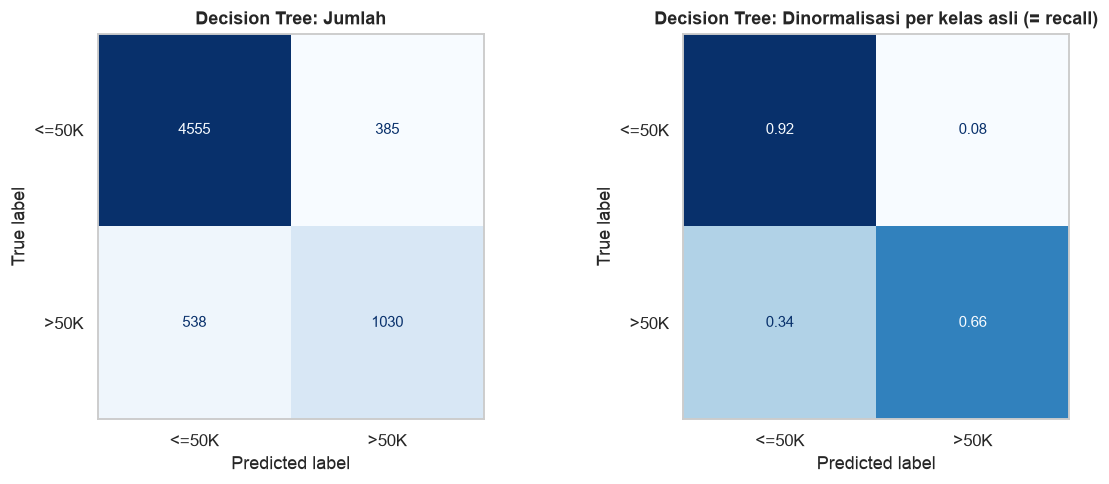

In [22]:
modelDt = gsDt.best_estimator_

# latih ulang satu model dengan hyperparameter terbaik untuk ukur waktu latih
t0 = time.perf_counter()
modelDt.fit(xLatih, yLatih)
waktuDt = time.perf_counter() - t0

predDt = modelDt.predict(xUji)
evaluasiModel("Decision Tree", yUji, predDt, waktuDt, gsDt.best_params_)
pohonDt = modelDt.named_steps["classifier"]
print(f"Kedalaman pohon : {pohonDt.get_depth()} | jumlah daun : {pohonDt.get_n_leaves()}")
gambarCm("Decision Tree", yUji, predDt)

pohon terbaik memakai kriteria `gini`, `max_depth=9`, dan `min_samples_leaf=5` (153 daun). akurasi uji 0,8582, F1 kelas `>50K` 0,6906 (precision 0,7279, recall 0,6569). skor ini hampir sama dengan skor CV (0,6874), jadi tidak ada tanda overfitting. batas kedalaman 9 dipilih dari grid 3 sampai 12 dan tanpa batas, jadi pohon yang lebih dalam malah lebih buruk di validasi.

pohon ini mengenali kelas `<=50K` dengan baik (recall 0,92), tapi cuma menemukan 66% orang `>50K`, hasil dari kelas yang lebih jarang dan batas keputusan standar 0,5.

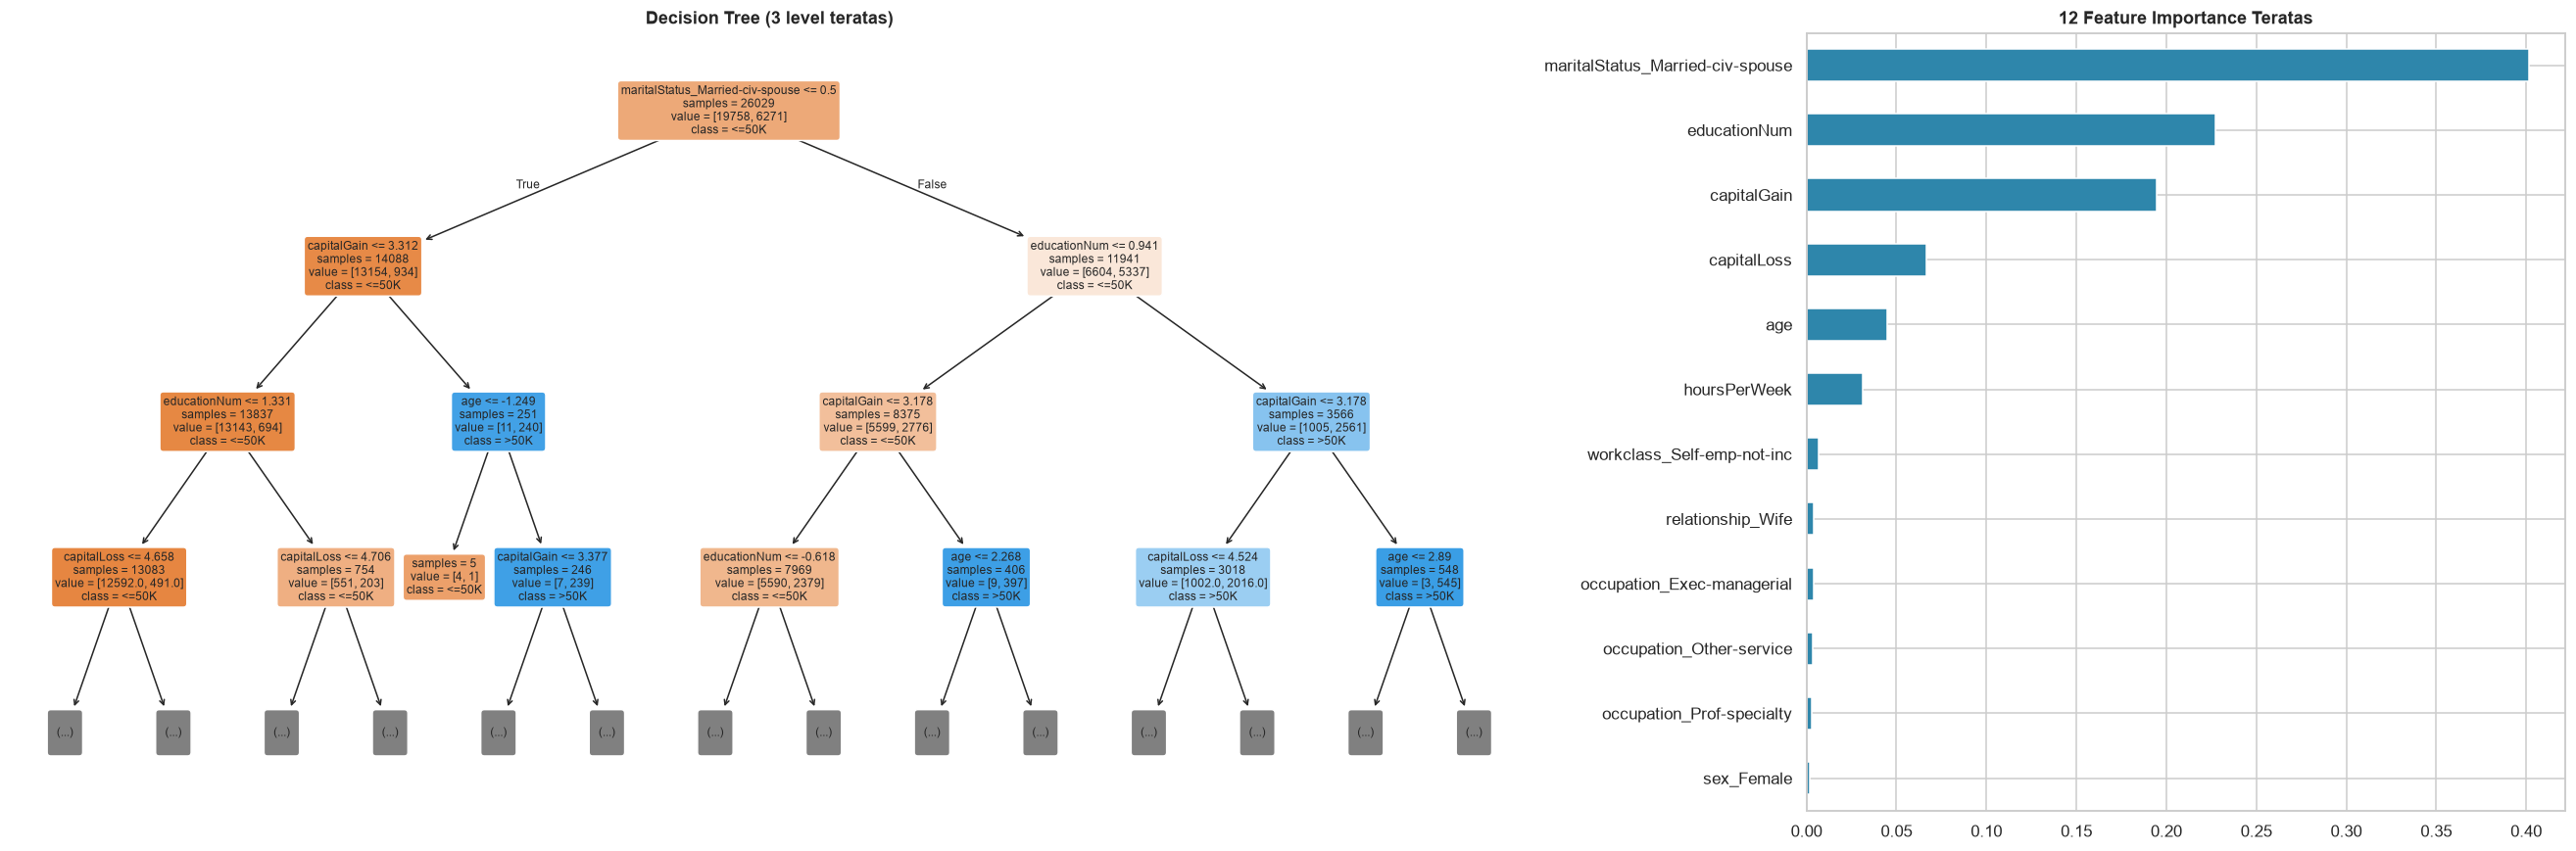

5 fitur terpenting: maritalStatus_Married-civ-spouse, educationNum, capitalGain, capitalLoss, age


In [23]:
namaFiturDt = [n.split("__", 1)[1] for n in modelDt.named_steps["preprocessor"].get_feature_names_out()]

fig, axes = plt.subplots(1, 2, figsize=(24, 8), gridspec_kw={"width_ratios": [2, 1]})
plot_tree(pohonDt, max_depth=3, feature_names=namaFiturDt, class_names=kelas, filled=True,
          rounded=True, fontsize=8, impurity=False, ax=axes[0])
axes[0].set_title("Decision Tree (3 level teratas)")

pentingnya = pd.Series(pohonDt.feature_importances_, index=namaFiturDt).sort_values().tail(12)
pentingnya.plot.barh(ax=axes[1], color="#2E86AB")
axes[1].set_title("12 Feature Importance Teratas")
plt.tight_layout()
plt.show()

print("5 fitur terpenting:", ", ".join(pd.Series(pohonDt.feature_importances_, index=namaFiturDt).sort_values(ascending=False).head(5).index))

split paling atas memakai `maritalStatus_Married-civ-spouse`, lalu `educationNum` dan `capitalGain`, sejalan dengan EDA. lima fitur terpenting adalah status menikah (sekitar 0,40), `educationNum` (sekitar 0,23), `capitalGain` (sekitar 0,19), `capitalLoss`, dan `age`. fitur kategorik lain (pekerjaan, ras, jenis kelamin) hampir tidak terpakai. angka ambang di node (mis. `capitalGain <= 3.312`) ada pada skala yang sudah di-log dan distandardisasi, bukan nilai asli.

support vector machine (SVM)

SVM kernel RBF waktu latihnya naik kira-kira kuadratik terhadap jumlah data, jadi grid search 5-fold di seluruh 26.029 baris latih akan sangat lambat. grid search dilakukan di subsampel 8.000 baris latih (stratified) untuk memilih kernel, `C`, dan `gamma`, lalu model terbaiknya dilatih ulang di seluruh data latih. konsekuensinya skor CV SVM (di subsampel) tidak bisa dibandingkan langsung dengan skor CV model lain.

In [24]:
pipaSvm = Pipeline([
    ("preprocessor", buatPreprocessor()),
    ("classifier", SVC(random_state=randomState)),
])
gridSvm = [
    {"classifier__kernel": ["rbf"], "classifier__C": [1, 3, 10], "classifier__gamma": ["scale", 0.005, 0.05]},
    {"classifier__kernel": ["linear"], "classifier__C": [0.1, 1]},
]

# tuning di subsampel 8.000 baris (xTuning), model akhir tetap dilatih di seluruh data latih
t0 = time.perf_counter()
gsSvm = GridSearchCV(pipaSvm, gridSvm, cv=cv, scoring="f1", n_jobs=-1)
gsSvm.fit(xTuning, yTuning)
waktuTuningSvm = time.perf_counter() - t0

print(f"Grid search selesai dalam {waktuTuningSvm:.1f} s ({len(gsSvm.cv_results_['params'])} kombinasi x 5 fold, 8.000 baris)")
print(f"F1 CV terbaik (subsampel) : {gsSvm.best_score_:.4f}")
print(f"Hyperparameter            : {gsSvm.best_params_}")
display(ringkasTuning(gsSvm))

Grid search selesai dalam 4.0 s (11 kombinasi x 5 fold, 8.000 baris)
F1 CV terbaik (subsampel) : 0.6566
Hyperparameter            : {'classifier__C': 10, 'classifier__gamma': 0.05, 'classifier__kernel': 'rbf'}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'C': 10, 'gamma': 0.05, 'kernel': 'rbf'}",0.6566,0.0204,1
1,"{'C': 3, 'gamma': 'scale', 'kernel': 'rbf'}",0.6565,0.0159,2
2,"{'C': 3, 'gamma': 0.05, 'kernel': 'rbf'}",0.6547,0.0126,3
3,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.6544,0.0150,4
4,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.6520,0.0109,5
5,"{'C': 10, 'gamma': 0.005, 'kernel': 'rbf'}",0.6479,0.0123,6
6,"{'C': 1, 'gamma': 0.05, 'kernel': 'rbf'}",0.6451,0.0085,7
7,"{'C': 3, 'gamma': 0.005, 'kernel': 'rbf'}",0.6446,0.0087,8


Hyperparameter terbaik: {'classifier__C': 10, 'classifier__gamma': 0.05, 'classifier__kernel': 'rbf'}
Akurasi            0.8617
Precision          0.7577
Recall             0.6263
F1                 0.6858
F1 (macro)         0.7986
Waktu latih (s)    4.3383 

Precision, Recall, dan F1 di atas dihitung untuk kelas positif (>50K).

              precision    recall  f1-score   support

       <=50K     0.8876    0.9364    0.9113      4940
        >50K     0.7577    0.6263    0.6858      1568

    accuracy                         0.8617      6508
   macro avg     0.8226    0.7814    0.7986      6508
weighted avg     0.8563    0.8617    0.8570      6508

Jumlah support vector : 8,667 dari 26,029 sampel latih


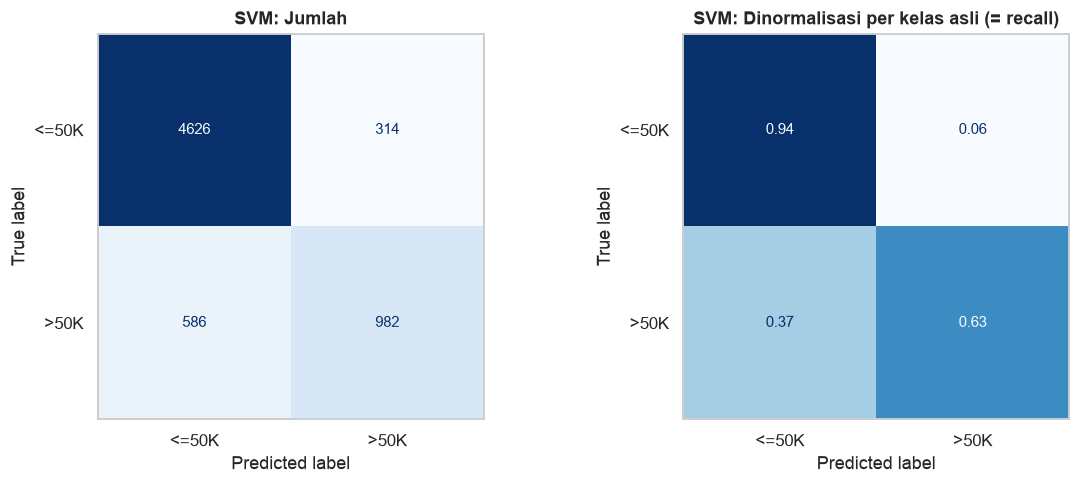

In [25]:
modelSvm = clone(gsSvm.best_estimator_)

t0 = time.perf_counter()
modelSvm.fit(xLatih, yLatih)
waktuSvm = time.perf_counter() - t0

predSvm = modelSvm.predict(xUji)
evaluasiModel("SVM", yUji, predSvm, waktuSvm, gsSvm.best_params_)
print(f"Jumlah support vector : {int(modelSvm.named_steps['classifier'].n_support_.sum()):,} dari {len(xLatih):,} sampel latih")
gambarCm("SVM", yUji, predSvm)

kombinasi terbaik adalah kernel RBF dengan `C=10` dan `gamma=0.05`, tapi lima kombinasi teratas berselisih kurang dari 0,005, jadi pilihannya tidak tajam. `C=10` dan `gamma=0.05` adalah nilai terbesar di grid, jadi nilai yang lebih besar tidak diuji. akurasi uji 0,8617 dan F1 0,6858 (precision 0,7577, recall 0,6263). dibanding model lain, SVM paling hati-hati: precision tertinggi tapi recall `>50K` terendah. sekitar sepertiga data latih (8.667 dari 26.029) jadi support vector.

artificial neural network (ANN / MLP)

In [26]:
pipaAnn = Pipeline([
    ("preprocessor", buatPreprocessor()),
    ("classifier", MLPClassifier(activation="relu", solver="adam", max_iter=500,
                                 early_stopping=True, n_iter_no_change=15,
                                 random_state=randomState)),
])
gridAnn = {
    "classifier__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
    "classifier__alpha": [1e-4, 1e-2],
    "classifier__learning_rate_init": [1e-3, 5e-3],
}

t0 = time.perf_counter()
gsAnn = GridSearchCV(pipaAnn, gridAnn, cv=cv, scoring="f1", n_jobs=-1)
gsAnn.fit(xLatih, yLatih)
waktuTuningAnn = time.perf_counter() - t0

print(f"Grid search selesai dalam {waktuTuningAnn:.1f} s ({len(gsAnn.cv_results_['params'])} kombinasi x 5 fold)")
print(f"F1 CV terbaik : {gsAnn.best_score_:.4f}")
print(f"Hyperparameter: {gsAnn.best_params_}")
display(ringkasTuning(gsAnn))

Grid search selesai dalam 11.6 s (16 kombinasi x 5 fold)
F1 CV terbaik : 0.6736
Hyperparameter: {'classifier__alpha': 0.0001, 'classifier__hidden_layer_sizes': (32,), 'classifier__learning_rate_init': 0.005}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'alpha': 0.0001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.005}",0.6736,0.0112,1
1,"{'alpha': 0.01, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.001}",0.6733,0.0111,2
2,"{'alpha': 0.01, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.005}",0.6728,0.0118,3
3,"{'alpha': 0.01, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.005}",0.6720,0.0152,4
4,"{'alpha': 0.0001, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.005}",0.6697,0.0052,5
5,"{'alpha': 0.01, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.001}",0.6695,0.0109,6
6,"{'alpha': 0.0001, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.005}",0.6692,0.0120,7
7,"{'alpha': 0.0001, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.001}",0.6689,0.0077,8


Hyperparameter terbaik: {'classifier__alpha': 0.0001, 'classifier__hidden_layer_sizes': (32,), 'classifier__learning_rate_init': 0.005}
Akurasi            0.8620
Precision          0.7445
Recall             0.6505
F1                 0.6943
F1 (macro)         0.8026
Waktu latih (s)    0.4488 

Precision, Recall, dan F1 di atas dihitung untuk kelas positif (>50K).

              precision    recall  f1-score   support

       <=50K     0.8933    0.9291    0.9109      4940
        >50K     0.7445    0.6505    0.6943      1568

    accuracy                         0.8620      6508
   macro avg     0.8189    0.7898    0.8026      6508
weighted avg     0.8575    0.8620    0.8587      6508

Iterasi sampai berhenti : 28 dari maks 500 | validation score terbaik : 0.8556


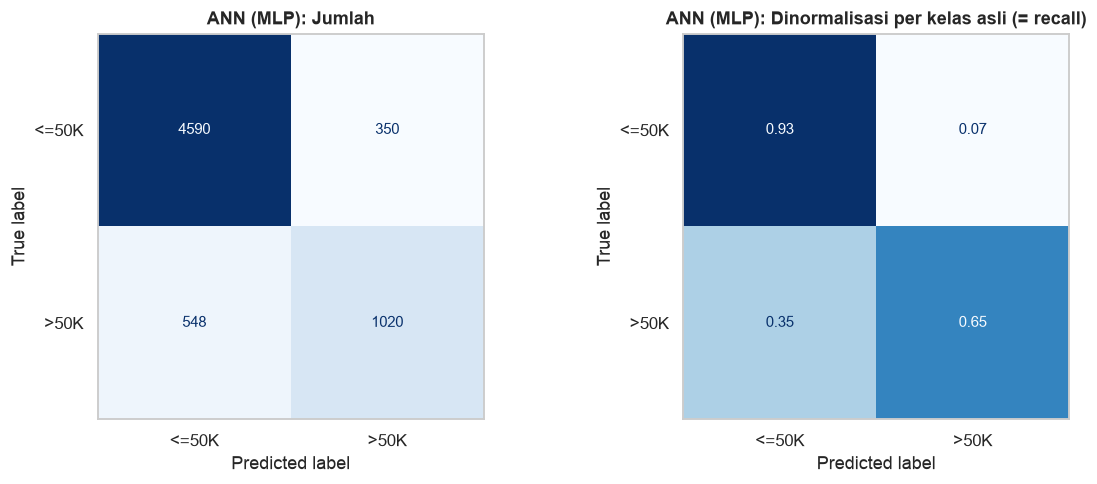

In [27]:
modelAnn = gsAnn.best_estimator_

t0 = time.perf_counter()
modelAnn.fit(xLatih, yLatih)
waktuAnn = time.perf_counter() - t0

predAnn = modelAnn.predict(xUji)
evaluasiModel("ANN (MLP)", yUji, predAnn, waktuAnn, gsAnn.best_params_)
mlp = modelAnn.named_steps["classifier"]
print(f"Iterasi sampai berhenti : {mlp.n_iter_} dari maks 500 | validation score terbaik : {max(mlp.validation_scores_):.4f}")
gambarCm("ANN (MLP)", yUji, predAnn)

arsitektur terbaik sederhana, satu hidden layer 32 neuron dengan `alpha=1e-4` dan `learning_rate_init=5e-3`, tapi konfigurasi lain (64 neuron, dua layer) berselisih di bawah 0,005 di CV. training berhenti otomatis di iterasi ke-28 lewat early stopping. akurasi uji 0,8620 dan F1 0,6943 (precision 0,7445, recall 0,6505).

deep learning: CNN 1D (PyTorch)

data kita tabular, bukan gambar atau sinyal, jadi CNN dipakai sebagai pembanding dengan cara memperlakukan 50 kolom hasil preprocessing sebagai deret satu dimensi (1 channel, panjang 50). arsitekturnya tiga blok `Conv1d` + `BatchNorm` + `ReLU` (16, 32, 64 filter), dua `MaxPool`, lalu dua lapisan `Linear` dengan `Dropout` 0,3. dilatih dengan Adam dan `CrossEntropyLoss`, memakai 15% data latih sebagai validasi untuk early stopping (sabar 8 epoch, bobot terbaik dipulihkan). ukurannya sengaja kecil (57 ribu parameter) karena data tidak butuh model besar.

keterbatasan konseptual: konvolusi mengasumsikan kolom yang bertetangga saling berhubungan (seperti piksel atau titik waktu), padahal urutan kolom di tabel ini arbitrer. kernel `Conv1d` jadi menggabungkan kolom yang kebetulan bersebelahan, seperti `age` dengan `educationNum` atau satu kategori pekerjaan dengan kategori berikutnya, yang tidak punya hubungan lokal.

In [28]:
class CNN1D(nn.Module):
    def __init__(self, nFitur: int, nKelas: int):
        super().__init__()
        self.ekstraksi = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=3, padding=1), nn.BatchNorm1d(16), nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.MaxPool1d(2),
        )
        self.klasifikasi = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * (nFitur // 4), 64), nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, nKelas),
        )

    def forward(self, x):
        return self.klasifikasi(self.ekstraksi(x))

# preprocessor yang sama dengan model lain, di-fit hanya pada data latih
prepCnn = buatPreprocessor().fit(xLatih)
xLatihS = prepCnn.transform(xLatih).astype(np.float32)
xUjiS = prepCnn.transform(xUji).astype(np.float32)
nFitur = xLatihS.shape[1]

torch.manual_seed(randomState)
print(CNN1D(nFitur, len(kelas)))
print("\nJumlah parameter:", sum(p.numel() for p in CNN1D(nFitur, len(kelas)).parameters()))

CNN1D(
  (ekstraksi): Sequential(
    (0): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (8): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (klasifikasi): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=768, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=2, bias

In [29]:
# pisahkan 15% data latih sebagai validasi untuk early stopping
xA, xV, yA, yV = train_test_split(xLatihS, yLatih, test_size=0.15,
                                  stratify=yLatih, random_state=randomState)

def buatLoader(xData, yData, acak: bool, seed: int = randomState, batch: int = 256) -> DataLoader:
    ds = TensorDataset(torch.from_numpy(xData).unsqueeze(1), torch.from_numpy(yData).long())
    return DataLoader(ds, batch_size=batch, shuffle=acak, generator=torch.Generator().manual_seed(seed))

loaderVal = buatLoader(xV, yV, acak=False)

fungsiLoss = nn.CrossEntropyLoss()
maksEpoch, sabar = 60, 8

def jalankanEpoch(model, loader, optimizer=None):
    # kalo optimizer dikasih berarti mode latih, kalo nggak mode evaluasi
    latih = optimizer is not None
    model.train(latih)
    totalLoss = totalBenar = n = 0
    with torch.set_grad_enabled(latih):
        for xb, yb in loader:
            keluaran = model(xb)
            loss = fungsiLoss(keluaran, yb)
            if latih:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            totalLoss += loss.item() * len(yb)
            totalBenar += (keluaran.argmax(1) == yb).sum().item()
            n += len(yb)
    return totalLoss / n, totalBenar / n

def latihCnn(seed: int, cetak: bool = True):
    # latih satu CNN dengan early stopping, balikin model dengan bobot terbaik
    torch.manual_seed(seed)
    model = CNN1D(nFitur, len(kelas))
    loaderLatih = buatLoader(xA, yA, acak=True, seed=seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

    riwayat = {"loss": [], "valLoss": [], "acc": [], "valAcc": []}
    valTerbaik, bobotTerbaik, tunggu, epochTerbaik = np.inf, None, 0, 0

    t0 = time.perf_counter()
    for epoch in range(1, maksEpoch + 1):
        loss, acc = jalankanEpoch(model, loaderLatih, optimizer)
        valLoss, valAcc = jalankanEpoch(model, loaderVal)
        for k, v in zip(riwayat, (loss, valLoss, acc, valAcc)):
            riwayat[k].append(v)

        if valLoss < valTerbaik - 1e-4:
            valTerbaik, tunggu, epochTerbaik = valLoss, 0, epoch
            bobotTerbaik = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            tunggu += 1

        if cetak and (epoch % 10 == 0 or epoch == 1):
            print(f"Epoch {epoch:3d} | loss {loss:.4f} acc {acc:.4f} | valLoss {valLoss:.4f} valAcc {valAcc:.4f}")
        if tunggu >= sabar:
            if cetak:
                print(f"Early stopping di epoch {epoch}")
            break

    waktu = time.perf_counter() - t0
    model.load_state_dict(bobotTerbaik)
    model.eval()
    return model, riwayat, epochTerbaik, valTerbaik, waktu

def prediksiCnn(model, xData) -> np.ndarray:
    with torch.no_grad():
        return model(torch.from_numpy(xData).unsqueeze(1)).argmax(1).numpy()

modelCnn, riwayat, epochTerbaik, valTerbaik, waktuCnn = latihCnn(randomState)
print(f"\nBobot terbaik dari epoch {epochTerbaik} (valLoss = {valTerbaik:.4f}) | waktu latih {waktuCnn:.1f} s")

Epoch   1 | loss 0.3628 acc 0.8272 | valLoss 0.3253 valAcc 0.8502


Epoch  10 | loss 0.3184 acc 0.8514 | valLoss 0.3123 valAcc 0.8551


Epoch  20 | loss 0.3088 acc 0.8564 | valLoss 0.3115 valAcc 0.8517


Epoch  30 | loss 0.3028 acc 0.8602 | valLoss 0.3098 valAcc 0.8556
Early stopping di epoch 30

Bobot terbaik dari epoch 22 (valLoss = 0.3054) | waktu latih 77.9 s


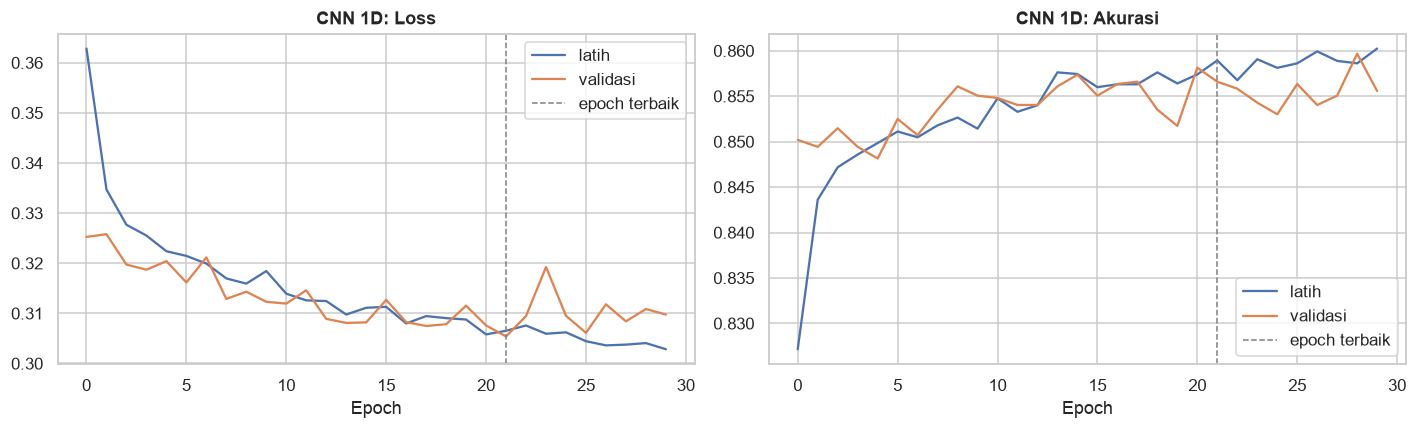

Hyperparameter terbaik: {'epochTerbaik': 22, 'optimizer': 'Adam lr=1e-3', 'batch': 256}
Akurasi             0.8642
Precision           0.7537
Recall              0.6480
F1                  0.6968
F1 (macro)          0.8047
Waktu latih (s)    77.9104 

Precision, Recall, dan F1 di atas dihitung untuk kelas positif (>50K).

              precision    recall  f1-score   support

       <=50K     0.8930    0.9328    0.9125      4940
        >50K     0.7537    0.6480    0.6968      1568

    accuracy                         0.8642      6508
   macro avg     0.8234    0.7904    0.8047      6508
weighted avg     0.8595    0.8642    0.8605      6508



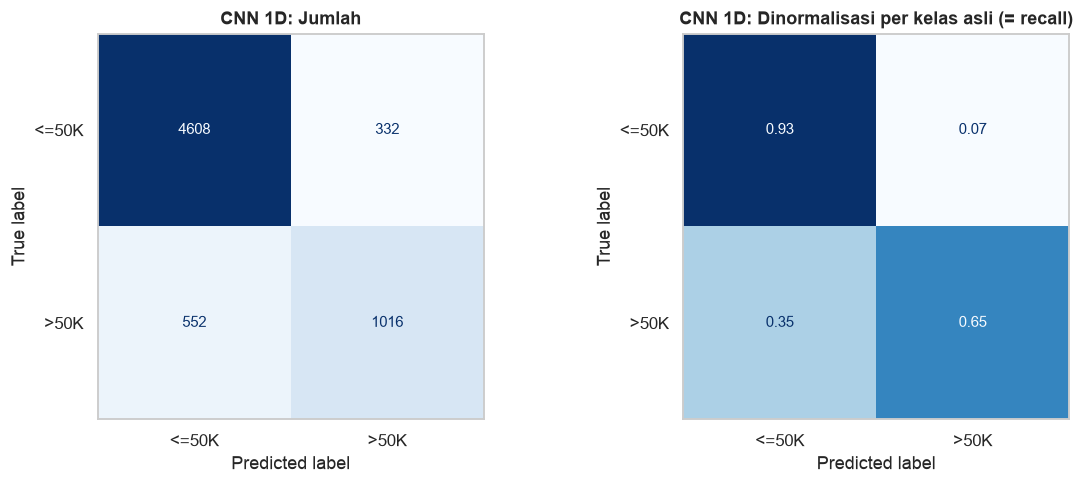

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(riwayat["loss"], label="latih")
axes[0].plot(riwayat["valLoss"], label="validasi")
axes[0].axvline(epochTerbaik - 1, ls="--", c="gray", lw=1, label="epoch terbaik")
axes[0].set_title("CNN 1D: Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(riwayat["acc"], label="latih")
axes[1].plot(riwayat["valAcc"], label="validasi")
axes[1].axvline(epochTerbaik - 1, ls="--", c="gray", lw=1, label="epoch terbaik")
axes[1].set_title("CNN 1D: Akurasi")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

predCnn = prediksiCnn(modelCnn, xUjiS)
evaluasiModel("CNN 1D", yUji, predCnn, waktuCnn,
              {"epochTerbaik": epochTerbaik, "optimizer": "Adam lr=1e-3", "batch": 256})
gambarCm("CNN 1D", yUji, predCnn)

loss validasi terkecil didapat di epoch ke-22 (0,3054), lalu mendatar sampai early stopping di epoch ke-30. selisih loss latih dan validasi kecil, jadi tidak overfit. akurasi uji 0,8642 dan F1 0,6968 (precision 0,7537, recall 0,6480). waktu latihnya sekitar 78 detik, jauh lebih lama dari tiga metode lain.

# Perbandingan hasil

In [31]:
tabelHasil = pd.DataFrame(hasilEvaluasi).T
tabelHasil.index.name = "Metode"
kolomMetrik = ["Akurasi", "Precision", "Recall", "F1", "F1 (macro)"]
tabelHasil = tabelHasil[kolomMetrik + ["Waktu latih (s)"]].sort_values("F1", ascending=False)

display(tabelHasil.style
        .format({**{k: "{:.4f}" for k in kolomMetrik}, "Waktu latih (s)": "{:.2f}"})
        .background_gradient(cmap="Greens", subset=kolomMetrik, axis=0))
print(f"Jumlah data uji : {len(yUji):,} (kelas >50K: {int(yUji.sum()):,})")

,Akurasi,Precision,Recall,F1,F1 (macro),Waktu latih (s)
Metode,,,,,,
CNN 1D,0.8642,0.7537,0.6480,0.6968,0.8047,77.91
ANN (MLP),0.8620,0.7445,0.6505,0.6943,0.8026,0.45
Decision Tree,0.8582,0.7279,0.6569,0.6906,0.7993,0.08
SVM,0.8617,0.7577,0.6263,0.6858,0.7986,4.34


Jumlah data uji : 6,508 (kelas >50K: 1,568)


urutan berdasarkan F1 kelas `>50K`: CNN 1D (0,6968), ANN (0,6943), Decision Tree (0,6906), lalu SVM (0,6858). selisih F1 antara yang tertinggi dan terendah cuma 0,011, dan akurasi keempatnya ada di rentang 0,858 sampai 0,864. keempat metode pada dasarnya setara. perbedaannya ada di jenis kesalahan: SVM punya precision tertinggi (0,7577) tapi recall terendah (0,6263), sedangkan Decision Tree sebaliknya, recall tertinggi (0,6569) dengan precision terendah (0,7279).

selang kepercayaan (bootstrap)

In [32]:
# bootstrap data uji 2000x buat dapat selang kepercayaan 95% akurasi dan F1 tiap model
rng = np.random.default_rng(randomState)
nUji, B = len(yUji), 2000
indeks = rng.integers(0, nUji, size=(B, nUji))

batas = {}
for nama, pred in prediksi.items():
    benar = (pred == yUji).astype(float)
    tp = ((pred == 1) & (yUji == 1)).astype(float)[indeks].sum(axis=1)
    fp = ((pred == 1) & (yUji == 0)).astype(float)[indeks].sum(axis=1)
    fn = ((pred == 0) & (yUji == 1)).astype(float)[indeks].sum(axis=1)
    akurasiBoot = benar[indeks].mean(axis=1)
    f1Boot = 2 * tp / (2 * tp + fp + fn)
    batas[nama] = (np.percentile(akurasiBoot, 2.5), np.percentile(akurasiBoot, 97.5),
                   np.percentile(f1Boot, 2.5), np.percentile(f1Boot, 97.5))

tabelCi = pd.DataFrame(batas, index=["akurasiBawah", "akurasiAtas", "f1Bawah", "f1Atas"]).T
tabelCi.insert(0, "F1", tabelHasil["F1"])
tabelCi.insert(0, "Akurasi", tabelHasil["Akurasi"])
display(tabelCi.sort_values("F1", ascending=False).round(4))

,Akurasi,F1,akurasiBawah,akurasiAtas,f1Bawah,f1Atas
CNN 1D,0.8642,0.6968,0.8554,0.8725,0.6772,0.7150
ANN (MLP),0.8620,0.6943,0.8530,0.8706,0.6745,0.7131
Decision Tree,0.8582,0.6906,0.8494,0.8669,0.6712,0.7096
SVM,0.8617,0.6858,0.8528,0.8706,0.6657,0.7059


selang kepercayaan 95% akurasi tiap model lebarnya sekitar 1,7 poin dan saling tumpang tindih, begitu juga untuk F1 (lebar sekitar 3,8 poin). selisih 0,01 antar model di atas ada di dalam selang itu, jadi dengan satu data uji sebesar ini urutan model belum bisa dikatakan benar-benar berbeda.

visualisasi perbandingan metrik dan waktu

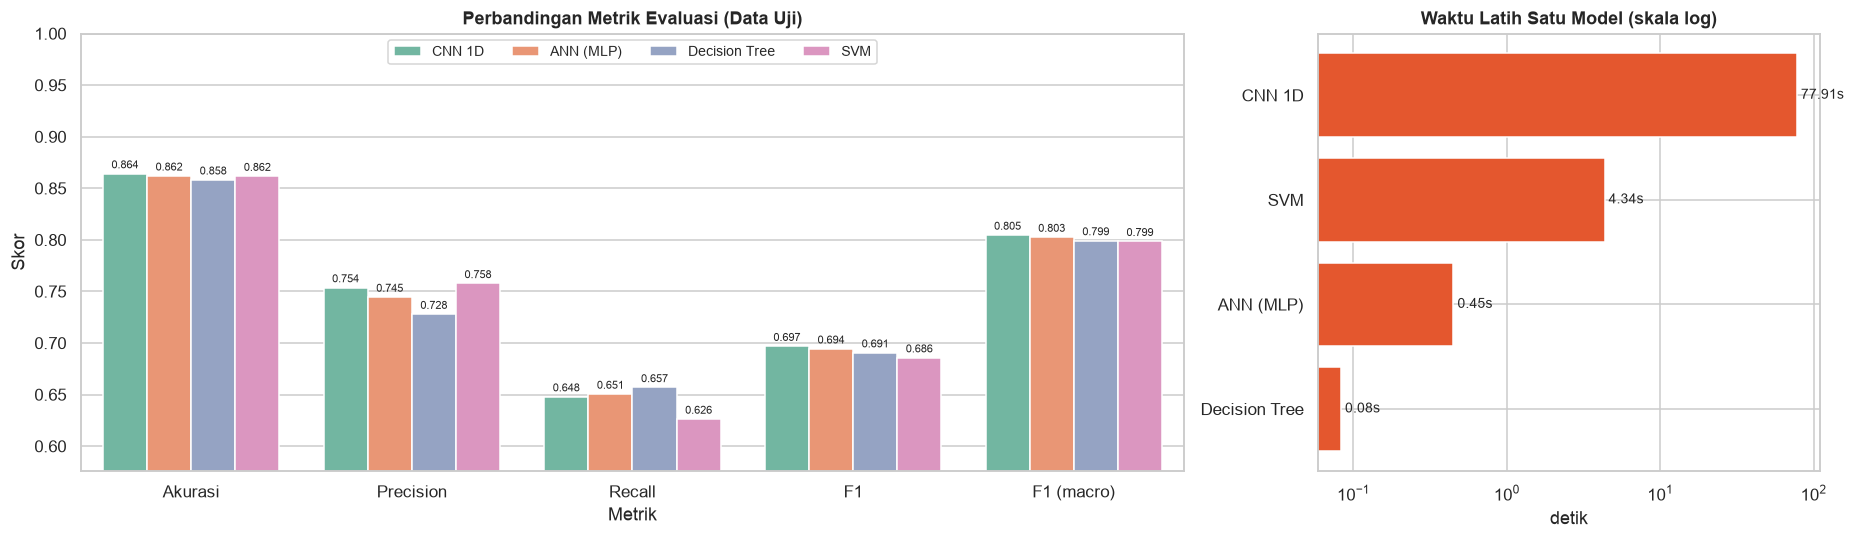

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [2.2, 1]})

dataPlot = tabelHasil[kolomMetrik].reset_index().melt(id_vars="Metode", var_name="Metrik", value_name="Skor")
sns.barplot(data=dataPlot, x="Metrik", y="Skor", hue="Metode", palette="Set2", ax=axes[0])
axes[0].set_ylim(max(0, dataPlot["Skor"].min() - 0.05), 1.0)
axes[0].set_title("Perbandingan Metrik Evaluasi (Data Uji)")
axes[0].legend(loc="upper center", ncol=4, fontsize=9)
for wadah in axes[0].containers:
    axes[0].bar_label(wadah, fmt="%.3f", fontsize=7, padding=2)

waktu = tabelHasil["Waktu latih (s)"].sort_values()
axes[1].barh(waktu.index, waktu.values, color="#E4572E")
axes[1].set_xscale("log")
for i, v in enumerate(waktu.values):
    axes[1].text(v, i, f" {v:.2f}s", va="center", fontsize=9)
axes[1].set_title("Waktu Latih Satu Model (skala log)")
axes[1].set_xlabel("detik")

plt.tight_layout()
plt.show()

pola precision, recall, dan F1 menunjukkan trade-off yang sama di semua model: precision di sekitar 0,73 sampai 0,76 dan recall di sekitar 0,63 sampai 0,66. akurasi dan F1 macro nyaris datar. di sisi waktu, bedanya jauh: Decision Tree sekitar 0,08 detik, ANN 0,5 detik, SVM sekitar 5 detik, dan CNN sekitar 78 detik (hampir seribu kali Decision Tree) untuk hasil yang tidak lebih baik.

performa per kelas

,precision <=50K,recall <=50K,precision >50K,recall >50K
Model,,,,
Decision Tree,0.8944,0.9221,0.7279,0.6569
SVM,0.8876,0.9364,0.7577,0.6263
ANN (MLP),0.8933,0.9291,0.7445,0.6505
CNN 1D,0.8930,0.9328,0.7537,0.6480


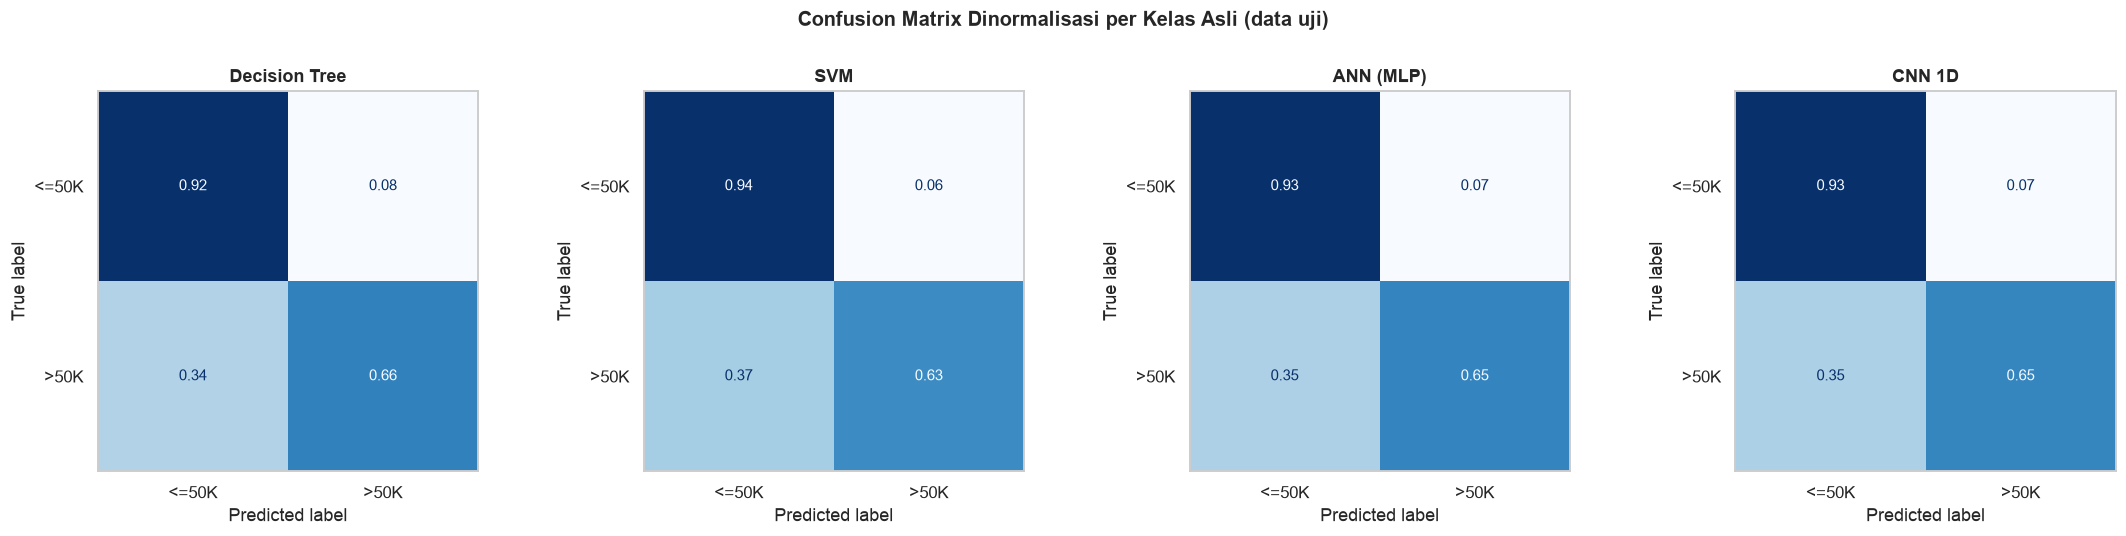

In [34]:
baris = []
for nama, pred in prediksi.items():
    p, r = precision_score(yUji, pred, average=None), recall_score(yUji, pred, average=None)
    baris.append({"Model": nama, "precision <=50K": p[0], "recall <=50K": r[0],
                  "precision >50K": p[1], "recall >50K": r[1]})
display(pd.DataFrame(baris).set_index("Model").round(4))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (nama, pred) in zip(axes, prediksi.items()):
    ConfusionMatrixDisplay.from_predictions(yUji, pred, display_labels=kelas, normalize="true", cmap="Blues",
                                            values_format=".2f", colorbar=False, ax=ax)
    ax.set_title(nama)
    ax.grid(False)
fig.suptitle("Confusion Matrix Dinormalisasi per Kelas Asli (data uji)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

semua model jauh lebih baik di kelas `<=50K` (precision 0,89 dan recall 0,92 sampai 0,94) daripada `>50K` (precision 0,73 sampai 0,76 dan recall 0,63 sampai 0,66). artinya sekitar sepertiga orang berpenghasilan `>50K` salah diprediksi sebagai `<=50K` oleh semua model. ini wajar karena kelas `>50K` cuma seperempat data dan batas keputusan masih standar 0,5. confusion matrix keempat model hampir identik.

skor CV vs skor uji

In [35]:
cvTerbaik = {"Decision Tree": gsDt.best_score_, "SVM": gsSvm.best_score_, "ANN (MLP)": gsAnn.best_score_}
konsistensi = pd.DataFrame({
    "F1 CV (latih)": pd.Series(cvTerbaik),
    "F1 uji":        tabelHasil["F1"].reindex(cvTerbaik.keys()),
})
konsistensi["selisih"] = konsistensi["F1 uji"] - konsistensi["F1 CV (latih)"]
display(konsistensi.round(4))

,F1 CV (latih),F1 uji,selisih
Decision Tree,0.6874,0.6906,0.0031
SVM,0.6566,0.6858,0.0292
ANN (MLP),0.6736,0.6943,0.0208


skor uji Decision Tree hampir sama dengan skor CV (selisih +0,003), sedangkan ANN lebih tinggi 0,021. SVM tampak naik 0,029, tapi skor CV-nya dari subsampel 8.000 baris sehingga tidak sebanding. tidak ada model yang skor ujinya turun jauh dari skor CV, jadi tidak ada tanda overfitting ke data latih. skor uji yang sedikit lebih tinggi masih dalam rentang variasi antar lipatan (simpangan baku CV sekitar 0,01).

uji signifikansi (McNemar) dan kestabilan terhadap seed

In [36]:
baris = []
for a, b in combinations(prediksi, 2):
    benarA, benarB = prediksi[a] == yUji, prediksi[b] == yUji
    hanyaA = int((benarA & ~benarB).sum())
    hanyaB = int((~benarA & benarB).sum())
    p = binomtest(hanyaA, hanyaA + hanyaB, 0.5).pvalue if hanyaA + hanyaB else 1.0
    baris.append((a, b, hanyaA, hanyaB, p, "ya" if p < 0.05 else "tidak"))

tabelMcnemar = pd.DataFrame(baris, columns=["Model A", "Model B", "A benar & B salah", "B benar & A salah",
                                             "p-value", "Beda signifikan (alpha=0.05)?"])
display(tabelMcnemar.round(4))

,Model A,Model B,A benar & B salah,B benar & A salah,p-value,Beda signifikan (alpha=0.05)?
0,Decision Tree,SVM,284,307,0.3655,tidak
1,Decision Tree,ANN (MLP),250,275,0.2949,tidak
2,Decision Tree,CNN 1D,233,272,0.0907,tidak
3,SVM,ANN (MLP),165,167,0.9562,tidak
4,SVM,CNN 1D,120,136,0.3485,tidak
5,ANN (MLP),CNN 1D,114,128,0.4034,tidak


In [37]:
seedUlang = [1, 2, 3, 4, 5]
hasilSeed = {"ANN (MLP)": [], "CNN 1D": []}
paramAnn = {k.replace("classifier__", ""): v for k, v in gsAnn.best_params_.items()}

for sd in seedUlang:
    # ANN: hyperparameter sama, cuma random_state yang diganti
    annUlang = Pipeline([
        ("preprocessor", buatPreprocessor()),
        ("classifier", MLPClassifier(activation="relu", solver="adam", max_iter=500, early_stopping=True,
                                     n_iter_no_change=15, random_state=sd, **paramAnn)),
    ]).fit(xLatih, yLatih)
    pred = annUlang.predict(xUji)
    hasilSeed["ANN (MLP)"].append((accuracy_score(yUji, pred), f1_score(yUji, pred)))

    # CNN: latih ulang dengan seed berbeda
    cnnUlang, *_ = latihCnn(sd, cetak=False)
    pred = prediksiCnn(cnnUlang, xUjiS)
    hasilSeed["CNN 1D"].append((accuracy_score(yUji, pred), f1_score(yUji, pred)))

ringkasSeed = pd.DataFrame({
    nama: {
        "Akurasi rata-rata": np.mean([a for a, _ in v]),
        "Akurasi std":       np.std([a for a, _ in v], ddof=1),
        "Akurasi min":       min(a for a, _ in v),
        "Akurasi maks":      max(a for a, _ in v),
        "F1 rata-rata":      np.mean([f for _, f in v]),
        "F1 std":            np.std([f for _, f in v], ddof=1),
    } for nama, v in hasilSeed.items()
}).T

print(f"Hasil 5 seed berbeda {seedUlang} pada data uji yang sama (DT dan SVM deterministik, tidak perlu diulang):")
display(ringkasSeed.round(4))

Hasil 5 seed berbeda [1, 2, 3, 4, 5] pada data uji yang sama (DT dan SVM deterministik, tidak perlu diulang):


,Akurasi rata-rata,Akurasi std,Akurasi min,Akurasi maks,F1 rata-rata,F1 std
ANN (MLP),0.8631,0.0022,0.8602,0.8659,0.7009,0.0085
CNN 1D,0.8610,0.0022,0.8583,0.8631,0.6872,0.0094


hasil McNemar:

tidak ada satu pun pasangan model yang berbeda signifikan (semua p > 0,05). yang paling mendekati adalah Decision Tree vs CNN (p = 0,09), sedangkan SVM vs ANN hampir identik (p = 0,96). jadi pada data uji ini keempat metode tidak terbukti berbeda dalam hal kesalahan prediksi.

kestabilan terhadap seed (DT dan SVM deterministik, jadi cuma ANN dan CNN yang diulang): akurasi ANN 0,8631 ± 0,0022 (rentang 0,8602 sampai 0,8659) dan F1 0,7009 ± 0,0085. CNN 0,8610 ± 0,0022 dan F1 0,6872 ± 0,0094. seed 42 yang dipakai di tabel utama (ANN 0,8620, CNN 0,8642) ada di dalam rentang ini, tapi ranking ANN dan CNN di tabel utama bisa terbalik kalau seed-nya diganti, jadi selisih antar keduanya tidak boleh dianggap nyata.

# Analisis dan kesimpulan

ringkasan hasil

| metode | akurasi | precision (>50K) | recall (>50K) | F1 (>50K) | waktu latih |
|---|---|---|---|---|---|
| CNN 1D | 0,8642 | 0,7537 | 0,6480 | 0,6968 | ± 78 detik |
| ANN / MLP (32) | 0,8620 | 0,7445 | 0,6505 | 0,6943 | ± 0,5 detik |
| decision tree (depth 9) | 0,8582 | 0,7279 | 0,6569 | 0,6906 | ± 0,08 detik |
| SVM (RBF, C=10) | 0,8617 | 0,7577 | 0,6263 | 0,6858 | ± 5 detik |

temuan utama:

1. **keempat metode setara.** akurasi 0,858 sampai 0,864 dan F1 kelas `>50K` 0,686 sampai 0,697. selang kepercayaan bootstrap saling tumpang tindih dan uji McNemar tidak menemukan satu pun pasangan yang berbeda signifikan (p terkecil 0,09).
2. **yang membedakan adalah jenis kesalahan dan biaya, bukan akurasi.** SVM paling hati-hati (precision tertinggi, recall terendah), Decision Tree sebaliknya, dan ANN serta CNN di antaranya.
3. **semua model lemah di kelas `>50K`.** recall cuma 0,63 sampai 0,66, jadi sekitar sepertiga orang berpenghasilan tinggi tidak terdeteksi. ini dipengaruhi ketidakseimbangan kelas dan ambang keputusan standar, bukan kekurangan satu metode saja.
4. **tidak ada overfitting berat.** skor uji tidak lebih rendah dari skor CV pada ketiga metode scikit-learn.
5. **fitur yang menentukan konsisten dengan EDA:** status menikah, pendidikan, keuntungan modal, dan usia. pohon keputusan hampir tidak memakai fitur kategorik lain.
6. **standardisasi terbukti penting untuk SVM** (F1 CV naik dari 0,49 ke 0,65), dan transformasi `log(1 + x)` pada `capitalGain` dan `capitalLoss` meredam pengaruh nilai ekstrem 99.999 tanpa membuang sinyalnya.

kelebihan dan kekurangan masing-masing metode

| kriteria | decision tree | SVM (RBF) | ANN (MLP) | CNN 1D |
|---|---|---|---|---|
| **akurasi dan F1 di dataset ini** | **+** setara (akurasi 0,8582), recall `>50K` tertinggi. | **+** setara (0,8617), precision `>50K` tertinggi tapi recall terendah. | **+** setara (0,8620), rata-rata lintas seed F1 0,7009. | **+** setara (0,8642), tapi rata-rata lintas seed F1 0,6872. |
| **interpretabilitas** | **+** paling mudah dibaca: aturan `fitur <= ambang` dan *feature importance*. pohon 153 daun cukup besar, tapi tiga level teratas sudah menjelaskan keputusan utama. | **−** sulit ditafsirkan (8.667 support vector). | **−** *black box*. | **−** *black box*, kernel konvolusi sulit dimaknai untuk kolom tabular. |
| **kebutuhan preprocessing** | **+** tidak butuh standardisasi, tahan skala dan outlier. | **−** wajib standardisasi (F1 CV turun 0,16 tanpa itu). | **−** sebaiknya distandardisasi. | **−** sebaiknya distandardisasi. |
| **waktu latih** | **+** paling cepat (± 0,08 detik). | **−** ± 5 detik di data latih penuh, dan tuning 5-fold di seluruh data terlalu lambat sehingga harus pakai subsampel. naik kira-kira kuadratik terhadap jumlah data. | **+** cepat (± 0,5 detik). | **−** ± 78 detik, hampir seribu kali Decision Tree untuk hasil yang sama. |
| **jumlah hyperparameter** | **+** sedikit (kedalaman, `min_samples_leaf`, kriteria). | **+** sedikit (`C`, `gamma`, kernel). | **−** lebih banyak (arsitektur, `alpha`, *learning rate*). | **−** paling banyak (arsitektur, optimizer, dropout, batch, epoch). |
| **stabilitas hasil** | **+** deterministik (tapi bisa berubah banyak kalau data latih sedikit berbeda). | **+** deterministik. | **−** bergantung seed (std F1 ± 0,009). | **−** bergantung seed (std F1 ± 0,009). |
| **kecocokan dengan jenis data** | **+** cocok untuk tabular campuran numerik dan kategorik. | **+** cukup cocok, tapi fitur kategorik harus di-encode. | **+** cocok untuk tabular. | **−** asumsi struktur lokal tidak terpenuhi karena urutan kolom tabular arbitrer. keunggulan CNN tidak termanfaatkan. |

kesimpulan

dataset ini punya dua masalah data yang perlu ditangani: nilai `?` (7,4% baris, terkait peluang penghasilan lebih rendah) dan fitur `capitalGain` dan `capitalLoss` yang hampir semuanya nol dengan nilai ekstrem. `?` dijadikan kategori sendiri, kedua fitur modal di-log, duplikat dan fitur yang tidak informatif atau kembar (`fnlwgt`, `education`) dibuang, dan semua transformasi dipasang di dalam pipeline supaya tidak ada kebocoran.

untuk memprediksi apakah penghasilan seseorang melebihi 50K, keempat metode mencapai akurasi sekitar 86% (F1 kelas `>50K` sekitar 0,69) dan tidak ada yang terbukti lebih baik dari yang lain. karena kemampuannya setara, pilihan metode bergantung pada kriteria lain:

| kriteria | metode | catatan |
|---|---|---|
| akurasi dan F1 tertinggi | tidak ada pemenang yang pasti | selisih ≤ 0,011 F1 dan di dalam selang kepercayaan |
| biaya komputasi terendah | **Decision Tree** | ± 0,08 detik vs ± 78 detik CNN |
| interpretabilitas | **Decision Tree** | aturan bisa dibaca, fitur penentu jelas |
| recall kelas `>50K` tertinggi | **Decision Tree** | 0,6569, tapi precision terendah |
| precision kelas `>50K` tertinggi | **SVM** | 0,7577, tapi recall terendah |
| rata-rata F1 lintas seed | **ANN** | 0,7009, tapi bergantung seed |

rekomendasi praktis untuk dataset ini adalah **Decision Tree**: performanya setara dengan metode yang lebih rumit, paling cepat dilatih, hasilnya deterministik, dan alasan prediksinya bisa dibaca. CNN tidak menambah akurasi yang bisa dibuktikan meski jauh lebih mahal, dan itu masuk akal karena datanya tabular, bukan gambar atau sinyal. kalau yang penting menghindari salah menandai orang sebagai berpenghasilan tinggi, SVM yang precision-nya paling tinggi bisa dipertimbangkan.

sisa kesalahan (± 14%) sebagian besar berasal dari orang `>50K` yang dikira `<=50K`. kemungkinan perbaikan berikutnya lebih bergantung pada penanganan ketidakseimbangan kelas (bobot kelas atau ambang keputusan yang disesuaikan) atau fitur tambahan daripada model yang lebih kompleks.

keterbatasan

- hasil berasal dari satu dataset dan satu pembagian 80/20. urutan metode belum tentu berlaku untuk data lain, dan selisih antar metode terlalu kecil untuk dibedakan dengan satu data uji.
- ambang keputusan tetap 0,5 dan tidak ada pembobotan kelas, jadi recall kelas `>50K` rendah (0,63 sampai 0,66). menurunkan ambang atau memakai `class_weight` bisa menaikkan recall dengan mengorbankan precision, dan tidak diuji di sini.
- tuning SVM dilakukan di subsampel 8.000 baris, bukan di seluruh data latih, dan nilai terbaik `C=10` dan `gamma=0.05` ada di batas atas grid, jadi nilai yang lebih besar tidak diuji. di data penuh nilai optimalnya bisa bergeser.
- grid hyperparameter terbatas (mis. MLP maksimal dua hidden layer), dan arsitektur CNN tidak di-tuning, cuma satu konfigurasi kecil.
- uji kestabilan seed hanya untuk ANN dan CNN dan memakai data uji yang sama, jadi variasi akibat pembagian data tidak terukur.
- `fnlwgt` dan `education` dibuang berdasarkan alasan di EDA dan tidak diuji dampaknya terhadap skor. `?` dijadikan kategori tersendiri dan tidak dibandingkan dengan imputasi modus.
- fitur `sex` dan `race` dipakai apa adanya karena ikut berkorelasi dengan target, tanpa analisis keadilan (*fairness*) pada prediksinya.
- waktu latih diukur sekali di satu mesin, jadi dipakai sebagai perbandingan orde besar, bukan angka presisi.